In [9]:
#importations de librairies
import pandas as pd
#*Pandas** est une bibliothèque pour la manipulation et l’analyse de données sous forme de **tableaux (DataFrames)**.
pd.options.mode.chained_assignment = None
#Supprime les alertes de copie (warnings) dans Pandas lorsque tu modifies une portion de DataFrame.
import seaborn as sns
#Seaborn est une bibliothèque de visualisation statistique basée sur Matplotlib.Elle permet de faire des graphiques élégants et analytiques (heatmaps, boxplots, pairplots, etc.).
import numpy as np
import matplotlib.pyplot as plt
import time
import csv
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

## Partie A — Compréhension du jeu de données (6 pts)

### Question 1 — Présentation de CIC-DDoS2019 (2 pts)

**Énoncé :** Présentation de CIC-DDoS2019 : origine, objectif, outil d'extraction des flux (CICFlowMeter), jours d'enregistrement, fichiers CSV fournis et leurs tailles. Comparer en quelques lignes avec NSL-KDD (nature des données, nombre de features, type d'attaques).

**Réponse :**

- **Origine :** jeu publié en 2019 par le Canadian Institute for Cybersecurity (CIC) de l'Université du Nouveau-Brunswick (Sharafaldin et al., 2019).
- **Objectif :** fournir un jeu réaliste et récent pour entraîner et évaluer des systèmes de détection d'attaques DDoS, en particulier les attaques par réflexion et par exploitation, absentes des anciens jeux.
- **Extraction des flux :** le trafic capturé (PCAP) a été converti en flux bidirectionnels avec **CICFlowMeter-V3**, qui calcule plus de 80 caractéristiques par flux (durée, nombre et taille des paquets, débits, drapeaux TCP, temps inter-arrivées...) et ajoute un `Label`.
- **Jours d'enregistrement :** 12 janvier 2019 (jour d'entraînement, 12 attaques : NTP, DNS, LDAP, MSSQL, NetBIOS, SNMP, SSDP, UDP, UDP-Lag, WebDDoS, SYN, TFTP) et 11 mars 2019 (jour de test, 7 attaques : Portmap, NetBIOS, LDAP, MSSQL, UDP, UDP-Lag, SYN).
- **Fichiers et tailles :** 18 fichiers CSV, environ 31 Go au total (11 fichiers dans `01-12`, environ 22 Go ; 7 fichiers dans `03-11`, environ 9 Go). La liste détaillée est affichée par la cellule de téléchargement ci-dessous.

**Comparaison avec NSL-KDD :**

| | CIC-DDoS2019 | NSL-KDD |
|---|---|---|
| Nature des données | Flux réseau extraits de trafic capturé en 2019 | Enregistrements de connexions issus de la simulation DARPA 1998 (version nettoyée de KDD'99) |
| Nombre de features | Plus de 80 features de flux (CICFlowMeter) | 41 features |
| Types d'attaques | DDoS modernes : réflexion (DNS, LDAP, NTP...) et exploitation (SYN, UDP, UDP-Lag) | 4 catégories : DoS, Probe, R2L, U2R |

Collecte des donnees

### Question 1 (suite) — Téléchargement, fichiers CSV fournis et leurs tailles

**Énoncé (extrait) :** Présentation de CIC-DDoS2019 : origine, objectif, outil d'extraction des flux (CICFlowMeter), jours d'enregistrement, fichiers CSV fournis et leurs tailles.

**Source des données :** version Kaggle *CIC-DDoS2019 30GB (Full Dataset CSV Files)* — https://www.kaggle.com/datasets/rodrigorosasilva/cic-ddos2019-30gb-full-dataset-csv-files (copie des CSV officiels du Canadian Institute for Cybersecurity, UNB).

In [10]:
import kagglehub, os, glob

# Téléchargement (public : en général aucun jeton n'est demandé)
path = kagglehub.dataset_download("rodrigorosasilva/cic-ddos2019-30gb-full-dataset-csv-files")
print("Dossier :", path)

# Lister les CSV et leur taille
csvs = sorted(glob.glob(os.path.join(path, "**", "*.csv"), recursive=True))
for f in csvs:
    print(f"{os.path.getsize(f)/1e9:6.2f} Go  {os.path.relpath(f, path)}")

Using Colab cache for faster access to the 'cic-ddos2019-30gb-full-dataset-csv-files' dataset.
Dossier : /kaggle/input/cic-ddos2019-30gb-full-dataset-csv-files
  2.13 Go  01-12/DrDoS_DNS.csv
  0.92 Go  01-12/DrDoS_LDAP.csv
  1.89 Go  01-12/DrDoS_MSSQL.csv
  0.65 Go  01-12/DrDoS_NTP.csv
  1.70 Go  01-12/DrDoS_NetBIOS.csv
  2.17 Go  01-12/DrDoS_SNMP.csv
  1.25 Go  01-12/DrDoS_SSDP.csv
  1.51 Go  01-12/DrDoS_UDP.csv
  0.64 Go  01-12/Syn.csv
  9.30 Go  01-12/TFTP.csv
  0.16 Go  01-12/UDPLag.csv
  0.87 Go  03-11/LDAP.csv
  2.39 Go  03-11/MSSQL.csv
  1.42 Go  03-11/NetBIOS.csv
  0.08 Go  03-11/Portmap.csv
  1.88 Go  03-11/Syn.csv
  1.79 Go  03-11/UDP.csv
  0.32 Go  03-11/UDPLag.csv


### Question 2 — Taxonomie des attaques (4 pts)

**Énoncé :** Lister toutes les valeurs de la colonne `Label` (BENIGN et chaque attaque), distinguer attaques par réflexion et attaques par exploitation, puis tracer un diagramme en barres de la distribution des classes en échelle logarithmique. Expliquer pourquoi l'échelle log est nécessaire ici.

*Les effectifs sont calculés sur les fichiers complets, en ne lisant que la colonne `Label` : la distribution montrée est donc la distribution réelle, et non celle de l'échantillon de la Q3.*

1. Valeurs de la colonne Label (effectifs réels, 70 427 637 flux au total)

Using Colab cache for faster access to the 'cic-ddos2019-30gb-full-dataset-csv-files' dataset.
18 fichiers CSV
TFTP             20082580
Syn               6473789
MSSQL             5787453
DrDoS_SNMP        5159870
DrDoS_DNS         5071011
DrDoS_MSSQL       4522492
DrDoS_NetBIOS     4093279
UDP               3867155
NetBIOS           3657497
DrDoS_UDP         3134645
DrDoS_SSDP        2610611
DrDoS_LDAP        2179930
LDAP              1915122
DrDoS_NTP         1202642
UDP-lag            366461
Portmap            186960
BENIGN             113828
UDPLag               1873
WebDDoS               439
dtype: int64


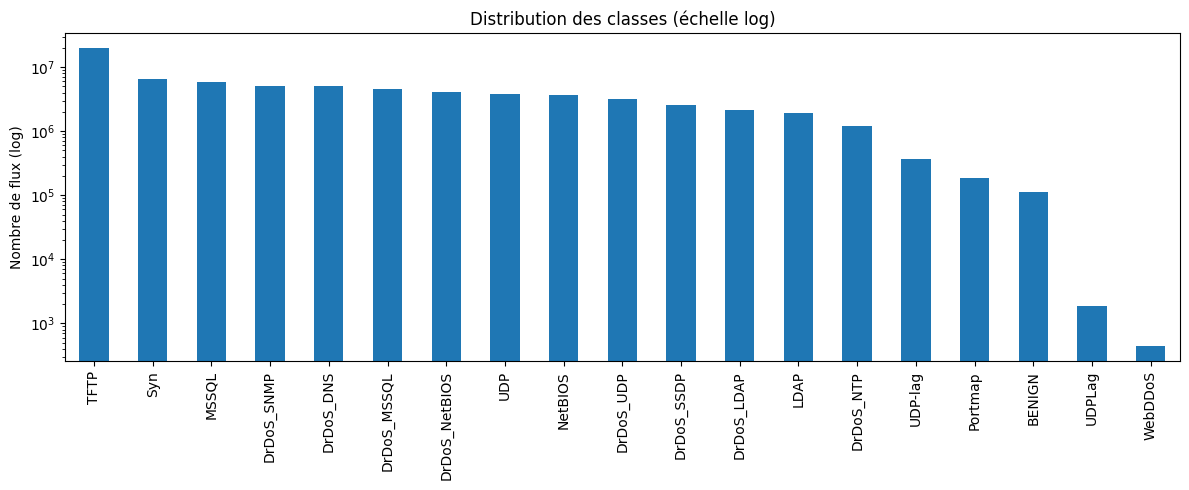

In [8]:
import os, glob, kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

path = kagglehub.dataset_download("rodrigorosasilva/cic-ddos2019-30gb-full-dataset-csv-files")
csvs = sorted(glob.glob(os.path.join(path, "**", "*.csv"), recursive=True))
print(len(csvs), "fichiers CSV")

compte = Counter()
for f in csvs:
    for chunk in pd.read_csv(f, usecols=lambda c: c.strip() == "Label", chunksize=1_000_000):
        compte.update(chunk.iloc[:, 0].str.strip())
labels = pd.Series(compte).sort_values(ascending=False)
print(labels)

labels.plot(kind="bar", logy=True, figsize=(12, 5), title="Distribution des classes (échelle log)")
plt.ylabel("Nombre de flux (log)"); plt.tight_layout(); plt.show()

**Réponse :**

**1. Valeurs de la colonne `Label`** (effectifs réels, 70 427 637 flux au total)

| Label | Nb de flux | Label | Nb de flux |
|---|---:|---|---:|
| TFTP | 20 082 580 | DrDoS_SSDP | 2 610 611 |
| Syn | 6 473 789 | DrDoS_LDAP | 2 179 930 |
| MSSQL | 5 787 453 | LDAP | 1 915 122 |
| DrDoS_SNMP | 5 159 870 | DrDoS_NTP | 1 202 642 |
| DrDoS_DNS | 5 071 011 | UDP-lag | 366 461 |
| DrDoS_MSSQL | 4 522 492 | Portmap | 186 960 |
| DrDoS_NetBIOS | 4 093 279 | **BENIGN** | **113 828** |
| UDP | 3 867 155 | UDPLag | 1 873 |
| NetBIOS | 3 657 497 | WebDDoS | 439 |
| DrDoS_UDP | 3 134 645 | | |

Le préfixe *DrDoS* signifie « Distributed Reflection DoS ». Une même attaque peut porter deux noms selon le jour d'enregistrement (DrDoS_LDAP / LDAP, DrDoS_MSSQL / MSSQL, DrDoS_NetBIOS / NetBIOS, DrDoS_UDP / UDP, UDP-lag / UDPLag). Il faudra harmoniser ces noms au prétraitement.

**2. Réflexion ou exploitation** (taxonomie de Sharafaldin et al., 2019)

| Catégorie | Principe | Labels |
|---|---|---|
| **Par réflexion** | L'attaquant usurpe l'IP de la victime et interroge des serveurs tiers légitimes. Ces serveurs renvoient des réponses, souvent amplifiées, vers la victime, et l'attaquant reste caché. | DrDoS_DNS, DrDoS_LDAP / LDAP, DrDoS_MSSQL / MSSQL, DrDoS_NTP, DrDoS_NetBIOS / NetBIOS, DrDoS_SNMP, DrDoS_SSDP, TFTP, Portmap |
| **Par exploitation** | L'attaque exploite une faiblesse d'un protocole pour épuiser directement les ressources de la victime. | Syn (poignée de main TCP), DrDoS_UDP / UDP (UDP flood), UDP-lag / UDPLag, WebDDoS |
| **Trafic normal** | | BENIGN |

**3. Pourquoi une échelle logarithmique ?**

Les classes sont extrêmement déséquilibrées. TFTP représente à lui seul **28,5 %** des flux (20 millions), alors que WebDDoS n'en compte que **439**, soit environ 45 700 fois moins : l'écart dépasse 4 ordres de grandeur. Le trafic BENIGN ne représente que **0,16 %** des flux.

Sur une échelle linéaire, les barres BENIGN, Portmap, UDPLag et WebDDoS seraient invisibles, écrasées par TFTP. L'échelle log affiche chaque puissance de 10 avec la même hauteur, ce qui permet de comparer toutes les classes sur un même graphique.

Ce déséquilibre a une conséquence pour la modélisation : l'accuracy seule serait trompeuse, car un modèle qui prédit toujours « attaque » obtiendrait 99,8 % d'accuracy. Il faudra donc suivre le F1 et le rappel par classe, et rééquilibrer les données, par exemple en plafonnant le nombre de flux par classe en Q3.

## Partie B — Chargement et exploration (5 pts)
### Question 3 — Chargement efficace (2 pts)

**Énoncé :** Charger les CSV (lecture par morceaux avec `chunksize` ou échantillonnage), réduire la mémoire en convertissant les types (float64 → float32, int64 → int32). Afficher la mémoire occupée avant et après avec `df.memory_usage(deep=True)`.

**Méthode d'échantillonnage :** le jeu complet compte 70,4 millions de flux (≈ 31 Go), ce qui dépasse la RAM de Colab. On fait donc un **échantillonnage stratifié avec plafond par classe** :

- Chaque CSV est lu **par morceaux de 500 000 lignes** (`chunksize`), pour ne jamais charger un fichier entier en mémoire.
- Pour chaque classe, le taux de tirage est `min(1, 50 000 / effectif réel)`, avec les effectifs réels calculés en Q2. On obtient environ 50 000 flux par classe d'attaque.
- Les classes rares (UDPLag : 1 873 ; WebDDoS : 439) sont **gardées en entier**.
- **BENIGN est gardé en entier** (113 828 flux), car c'est la seule classe de trafic normal, indispensable à la cible binaire.
- Le tirage est aléatoire avec une graine fixe (`random_state = 42`), donc reproductible.

Un simple tirage uniforme de 10 % aurait conservé le déséquilibre : environ 2 millions de flux TFTP contre 44 WebDDoS. Le plafond réduit fortement la mémoire tout en gardant assez d'exemples pour chaque classe.

In [12]:
import numpy as np
import pandas as pd

np.random.seed(42)
rng = np.random.default_rng(42)

MAX_PAR_CLASSE = 50_000
CHUNKSIZE = 500_000

# Taux de tirage par classe, à partir des effectifs réels de la Q2 (variable `labels`)
taux = {lab: min(1.0, MAX_PAR_CLASSE / n) for lab, n in labels.items()}
taux["BENIGN"] = 1.0          # on garde tout le trafic normal

morceaux = []
for f in csvs:
    for chunk in pd.read_csv(f, chunksize=CHUNKSIZE, low_memory=False):
        chunk.columns = chunk.columns.str.strip()          # " Label" -> "Label"
        chunk["Label"] = chunk["Label"].str.strip()
        p = chunk["Label"].map(taux).fillna(1.0).to_numpy()
        morceaux.append(chunk[rng.random(len(chunk)) < p])  # tirage stratifié
    print(f"{os.path.basename(f):22s} lu")

df = pd.concat(morceaux, ignore_index=True)
del morceaux

print("\nTaille de l'échantillon :", df.shape)
print(df["Label"].value_counts())

# ---------- Mémoire AVANT ----------
mem_avant = df.memory_usage(deep=True).sum() / 1e6
print(f"\nMémoire avant : {mem_avant:,.1f} Mo")
print(df.dtypes.value_counts())

# ---------- Réduction des types ----------
for col in df.select_dtypes("float64").columns:
    df[col] = df[col].astype("float32")
for col in df.select_dtypes("int64").columns:
    df[col] = df[col].astype("int32")

# ---------- Mémoire APRÈS ----------
mem_apres = df.memory_usage(deep=True).sum() / 1e6
print(f"\nMémoire après : {mem_apres:,.1f} Mo  (gain : {100*(1 - mem_apres/mem_avant):.1f} %)")
print(df.dtypes.value_counts())

DrDoS_DNS.csv          lu
DrDoS_LDAP.csv         lu
DrDoS_MSSQL.csv        lu
DrDoS_NTP.csv          lu
DrDoS_NetBIOS.csv      lu
DrDoS_SNMP.csv         lu
DrDoS_SSDP.csv         lu
DrDoS_UDP.csv          lu
Syn.csv                lu
TFTP.csv               lu
UDPLag.csv             lu
LDAP.csv               lu
MSSQL.csv              lu
NetBIOS.csv            lu
Portmap.csv            lu
Syn.csv                lu
UDP.csv                lu
UDPLag.csv             lu

Taille de l'échantillon : (916769, 88)
Label
BENIGN           113828
TFTP              50402
Syn               50371
NetBIOS           50209
Portmap           50174
DrDoS_MSSQL       50152
LDAP              50135
DrDoS_SSDP        50112
DrDoS_UDP         50068
DrDoS_SNMP        49977
DrDoS_NetBIOS     49939
DrDoS_LDAP        49928
DrDoS_DNS         49916
UDP-lag           49880
DrDoS_NTP         49866
MSSQL             49796
UDP               49704
UDPLag             1873
WebDDoS             439
Name: count, dtype: int64

Mém

**Résultat :** l'échantillon contient **916 769 flux × 88 colonnes** : environ 50 000 flux par classe d'attaque, BENIGN complet (113 828 flux), UDPLag (1 873) et WebDDoS (439) complets. La mémoire passe de **955,4 Mo à 654,7 Mo**, soit un gain de **31,5 %**.

Le gain est inférieur à 50 % parce que seules les 82 colonnes numériques (45 float64 et 37 int64) sont divisées par deux : environ 600 Mo deviennent environ 300 Mo. Les 6 colonnes texte (`object` : Flow ID, Source IP, Destination IP, Timestamp, SimillarHTTP, Label) pèsent à elles seules environ 350 Mo et ne changent pas. Elles seront supprimées en Q5, car ce sont des identifiants. La perte de précision du float32 est négligeable pour des débits, durées ou compteurs.

In [15]:
from google.colab import drive
drive.mount("/content/drive")

CACHE = "/content/drive/MyDrive/CICDDoS2019_cache"
os.makedirs(CACHE, exist_ok=True)

# Les colonnes texte (Flow ID, IP, SimillarHTTP…) mélangent chaînes et nombres :
# Parquet exige un seul type par colonne, on les convertit donc en texte.
obj_cols = df.select_dtypes("object").columns
df[obj_cols] = df[obj_cols].astype(str)

df.to_parquet(f"{CACHE}/echantillon_q3.parquet", index=False)   # échantillon (~100 Mo)
labels.to_frame("n").to_parquet(f"{CACHE}/labels_q2.parquet")   # effectifs de la Q2
print("Cache enregistré dans Google Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cache enregistré dans Google Drive


In [ ]:
# ⚡ RECHARGEMENT RAPIDE (environ 5 s) — à utiliser après un redémarrage de session
# Remplace l'exécution des Q2 et Q3 (environ 25 min), à condition que la cellule
# précédente ait été exécutée au moins une fois. Ensuite, reprendre à la Q4.
from google.colab import drive
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

drive.mount("/content/drive")
CACHE = "/content/drive/MyDrive/CICDDoS2019_cache"

df = pd.read_parquet(f"{CACHE}/echantillon_q3.parquet")      # échantillon de la Q3 (types float32 / int32 conservés)
labels = pd.read_parquet(f"{CACHE}/labels_q2.parquet")["n"]  # effectifs réels de la Q2
np.random.seed(42)

print("df :", df.shape)   # attendu : (916769, 88)
print(f"Mémoire : {df.memory_usage(deep=True).sum()/1e6:,.1f} Mo")

### Question 4 — Nettoyage des noms de colonnes (1 pt)

**Énoncé :** Supprimer les espaces en début de nom (ex. " Label"), uniformiser en snake_case, repérer et traiter les colonnes en double (ex. Fwd Header Length.1). Afficher la liste finale des colonnes.

**Démarche :**

- **Espaces :** dans les CSV d'origine, la plupart des noms commencent par une espace (" Label", " Flow Duration"). Ils ont déjà été retirés avec `str.strip()` pendant le chargement (Q3). On revérifie ici.
- **snake_case :** tout en minuscules ; les espaces, « / » et autres symboles sont remplacés par « _ » (ex. `Flow Bytes/s` → `flow_bytes_s`). Cela donne des noms homogènes, sans espaces, faciles à manipuler (`df.flow_duration`) et compatibles avec Parquet (Q16).
- **Doublons :** CICFlowMeter écrit deux fois la colonne `Fwd Header Length`, et pandas renomme la seconde en `Fwd Header Length.1`. On vérifie que leurs valeurs sont identiques, puis on supprime la copie. On recherche aussi toute autre paire de colonnes au contenu strictement identique. Une colonne dupliquée n'apporte aucune information, alourdit la mémoire et fausse la matrice de corrélation (Q10).

In [16]:
import re

# 1) Espaces en début / fin de nom
print("Noms avec espaces :", [c for c in df.columns if c != c.strip()])
df.columns = df.columns.str.strip()

# 2) Colonnes en double par le NOM (suffixe .1 ajouté par pandas)
doublons_nom = [c for c in df.columns if re.search(r"\.\d+$", c)]
for c in doublons_nom:
    orig = re.sub(r"\.\d+$", "", c)
    identique = df[c].equals(df[orig])
    print(f"{c!r} vs {orig!r} -> valeurs identiques : {identique}")

# 3) Colonnes en double par le CONTENU (hors colonnes constantes, traitées en Q8)
non_constantes = [c for c in df.columns if df[c].nunique(dropna=False) > 1]
hashes = {c: pd.util.hash_pandas_object(df[c], index=False).sum() for c in non_constantes}
vus, doublons_contenu = {}, []
for c, h in hashes.items():
    if h in vus and df[c].equals(df[vus[h]]):
        doublons_contenu.append((c, vus[h]))
    else:
        vus.setdefault(h, c)
print("Doublons de contenu (copie, original) :", doublons_contenu)

a_supprimer = sorted({c for c, _ in doublons_contenu} | set(doublons_nom))
df = df.drop(columns=a_supprimer)
print("Colonnes supprimées :", a_supprimer)

# 4) snake_case
def snake(nom):
    nom = re.sub(r"[^0-9a-zA-Z]+", "_", nom.strip())   # symboles -> _
    nom = re.sub(r"([a-z])([A-Z])", r"\1_\2", nom)      # SimillarHTTP -> Simillar_HTTP
    return re.sub(r"_+", "_", nom).strip("_").lower()

df.columns = [snake(c) for c in df.columns]
assert df.columns.is_unique, "Deux colonnes ont le même nom après conversion"

print(f"\n{df.shape[1]} colonnes finales :")
print(pd.Series(df.columns).to_string())

Noms avec espaces : []
'Fwd Header Length.1' vs 'Fwd Header Length' -> valeurs identiques : True
Doublons de contenu (copie, original) : [('RST Flag Count', 'Fwd PSH Flags'), ('Avg Fwd Segment Size', 'Fwd Packet Length Mean'), ('Avg Bwd Segment Size', 'Bwd Packet Length Mean'), ('Fwd Header Length.1', 'Fwd Header Length'), ('Subflow Fwd Packets', 'Total Fwd Packets'), ('Subflow Bwd Packets', 'Total Backward Packets')]
Colonnes supprimées : ['Avg Bwd Segment Size', 'Avg Fwd Segment Size', 'Fwd Header Length.1', 'RST Flag Count', 'Subflow Bwd Packets', 'Subflow Fwd Packets']

82 colonnes finales :
0                       unnamed_0
1                         flow_id
2                       source_ip
3                     source_port
4                  destination_ip
5                destination_port
6                        protocol
7                       timestamp
8                   flow_duration
9               total_fwd_packets
10         total_backward_packets
11    total_length_of_f

**Résultat :** aucun nom ne contenait encore d'espace (déjà nettoyés en Q3). **6 colonnes en double** ont été supprimées, et le jeu passe de **88 à 82 colonnes** :

| Copie supprimée | Original conservé | Explication |
|---|---|---|
| `Fwd Header Length.1` | `Fwd Header Length` | Même colonne écrite deux fois par CICFlowMeter (doublon de nom, valeurs identiques) |
| `Avg Fwd Segment Size` | `Fwd Packet Length Mean` | Même calcul : taille moyenne des paquets aller |
| `Avg Bwd Segment Size` | `Bwd Packet Length Mean` | Même calcul : taille moyenne des paquets retour |
| `Subflow Fwd Packets` | `Total Fwd Packets` | Chaque flux ne contient qu'un sous-flux, donc les compteurs sont égaux |
| `Subflow Bwd Packets` | `Total Backward Packets` | Idem pour le sens retour |
| `RST Flag Count` | `Fwd PSH Flags` | Valeurs strictement identiques sur tout l'échantillon (artefact de CICFlowMeter) |

Les colonnes **constantes** (toujours égales à 0, comme `Fwd URG Flags` ou les colonnes `*Bulk*`) sont aussi « égales entre elles », mais ce ne sont pas de vrais doublons : elles sont volontairement exclues ici et traitées en Q8.

Tous les noms sont maintenant en snake_case (ex. `flow_bytes_s`, `fwd_header_length`, `init_win_bytes_forward`), et la cible s'appelle désormais `label`.

### Question 5 — Colonnes identifiantes (2 pts)

**Énoncé :** Identifier les colonnes qui ne décrivent pas le comportement du flux (Unnamed: 0, Flow ID, Source IP, Destination IP, Source Port, Timestamp, SimillarHTTP…). Expliquer pourquoi les conserver créerait une fuite de données, puis les supprimer.

**Colonnes identifiantes retenues :**

| Colonne | Nature | Pourquoi la supprimer |
|---|---|---|
| `unnamed_0` | Index de ligne écrit dans le CSV | Simple numéro d'ordre, propre à chaque fichier et donc à chaque attaque |
| `flow_id` | Concaténation IP src – IP dst – ports – protocole | Identifiant unique de la connexion, redondant avec les IP et ports |
| `source_ip`, `destination_ip` | Adresses du banc d'essai CIC | Victimes (192.168.50.x) et attaquants fixes : elles désignent la machine, pas le comportement |
| `source_port`, `destination_port` | Ports | Les ports ne sont pas aléatoires : chaque outil d'attaque du banc d'essai réutilise le même port (ex. 900 pour LDAP, 634 pour NTP, 564 pour DNS, 80 pour WebDDoS, 443 pour BENIGN). Ces valeurs sont propres au banc d'essai et ne se généralisent pas. |
| `timestamp` | Date et heure du flux | Chaque attaque a été lancée dans une plage horaire précise (voir Q1) : l'heure suffit à deviner le label |
| `simillar_http` | Chaîne HTTP brute (presque toujours vide ou « 0 ») | Texte non structuré, pas une mesure du flux |

On garde `protocol` (TCP / UDP, une vraie propriété du flux, encodée en Q11) et `inbound` (sens du flux).

**Pourquoi c'est une fuite de données :** ces colonnes sont liées à la façon dont le jeu a été construit (une plage horaire, des IP et un fichier par attaque), pas au comportement réseau. Un modèle les utiliserait comme raccourci, par exemple « IP 172.16.0.5 à 10 h 52 ⇒ DNS », et obtiendrait un score presque parfait sur le test. En situation réelle, avec d'autres IP, d'autres heures et d'autres ports, il serait incapable de détecter l'attaque. Un IDS doit apprendre des **caractéristiques statistiques du flux** (durée, tailles, débits, drapeaux) qui se généralisent à d'autres réseaux.

In [17]:
ID_COLS = ["unnamed_0", "flow_id", "source_ip", "destination_ip",
           "source_port", "destination_port", "timestamp", "simillar_http"]
ID_COLS = [c for c in ID_COLS if c in df.columns]

# --- Preuve de la fuite : une IP / une heure suffisent-elles à deviner le label ? ---
for col in ["source_ip", "timestamp", "source_port"]:
    pur = (df.groupby(col)["label"].nunique() == 1).mean()
    print(f"{col:15s} : {df[col].nunique():>8,} valeurs distinctes, "
          f"{100*pur:5.1f} % d'entre elles n'apparaissent qu'avec un seul label")

print("\nPorts sources les plus fréquents par attaque :")
print(df.groupby("label")["source_port"].agg(lambda s: s.mode().iat[0]).to_string())

# --- Suppression ---
avant = df.shape
mem_avant = df.memory_usage(deep=True).sum() / 1e6
df = df.drop(columns=ID_COLS)
mem_apres = df.memory_usage(deep=True).sum() / 1e6

print(f"\nColonnes supprimées ({len(ID_COLS)}) : {ID_COLS}")
print(f"Taille : {avant} -> {df.shape}")
print(f"Mémoire : {mem_avant:,.1f} Mo -> {mem_apres:,.1f} Mo")
print("Colonnes texte restantes :", df.select_dtypes("object").columns.tolist())

source_ip       :    1,577 valeurs distinctes,  99.8 % d'entre elles n'apparaissent qu'avec un seul label
timestamp       :  912,204 valeurs distinctes, 100.0 % d'entre elles n'apparaissent qu'avec un seul label
source_port     :   59,526 valeurs distinctes,  10.2 % d'entre elles n'apparaissent qu'avec un seul label

Ports sources les plus fréquents par attaque :
label
BENIGN             443
DrDoS_DNS          564
DrDoS_LDAP         900
DrDoS_MSSQL      61850
DrDoS_NTP          634
DrDoS_NetBIOS      648
DrDoS_SNMP         672
DrDoS_SSDP         672
DrDoS_UDP          672
LDAP               900
MSSQL            61850
NetBIOS            648
Portmap            648
Syn              61850
TFTP             62468
UDP              61850
UDP-lag            672
UDPLag           61850
WebDDoS             80

Colonnes supprimées (8) : ['unnamed_0', 'flow_id', 'source_ip', 'destination_ip', 'source_port', 'destination_port', 'timestamp', 'simillar_http']
Taille : (916769, 82) -> (916769, 74)
Mémoi

**Résultat :** la fuite est confirmée par les données.

- **`source_ip`** : sur 1 577 adresses distinctes, **99,8 %** n'apparaissent qu'avec un seul label. Connaître l'IP revient presque à connaître l'attaque.
- **`timestamp`** : **100 %** des 912 204 horodatages correspondent à un seul label, car chaque attaque a été jouée dans sa propre plage horaire.
- **`source_port`** : seuls 10,2 % des ports sont « purs », mais le port dominant identifie la famille d'attaque (900 → LDAP, 634 → NTP, 564 → DNS, 80 → WebDDoS, 443 → BENIGN).

Après suppression des 8 colonnes, le jeu passe de 916 769 × 82 à 916 769 × 74, et la mémoire de 633,7 Mo à 319,4 Mo (−49,6 %, car ces colonnes texte étaient les plus lourdes). Seule la cible `label` reste au format texte.

## Partie C — Qualité des données (9 pts)
### Question 6 — Valeurs manquantes et infinies (3 pts)

**Énoncé :** Compter les NaN et les valeurs +inf / -inf par colonne (notamment Flow Bytes/s et Flow Packets/s). Justifier par un graphique (carte de chaleur ou barres par colonne). Choisir et justifier une stratégie : suppression des lignes, imputation par la médiane, etc.

**Origine attendue :** CICFlowMeter calcule `flow_bytes_s = octets / durée` et `flow_packets_s = paquets / durée`. Quand un flux ne contient qu'un seul paquet, sa durée vaut 0. La division donne alors **+inf** (x / 0) ou **NaN** (0 / 0). Ce sont des erreurs de calcul de l'outil, pas des mesures réelles.

In [18]:
num_cols = df.select_dtypes("number").columns

diag = pd.DataFrame({
    "NaN":  df[num_cols].isna().sum(),
    "+inf": np.isposinf(df[num_cols]).sum(),
    "-inf": np.isneginf(df[num_cols]).sum(),
})
diag["total"] = diag.sum(axis=1)
diag["% lignes"] = 100 * diag["total"] / len(df)
diag_pb = diag[diag["total"] > 0].sort_values("total", ascending=False)

print(f"{len(diag_pb)} colonne(s) concernée(s) sur {len(num_cols)} :")
print(diag_pb)

lignes_pb = df[num_cols].isna().any(axis=1) | np.isinf(df[num_cols]).any(axis=1)
print(f"\nLignes avec au moins un NaN ou un inf : {lignes_pb.sum():,} "
      f"({100*lignes_pb.mean():.2f} % du jeu)")

# Hypothèse : ces valeurs viennent des flux de durée nulle
print("Dont flow_duration == 0 :", (df.loc[lignes_pb, "flow_duration"] == 0).sum())

2 colonne(s) concernée(s) sur 73 :
                 NaN   +inf  -inf  total  % lignes
flow_bytes_s    6653  20928     0  27581  3.008501
flow_packets_s     0  27581     0  27581  3.008501

Lignes avec au moins un NaN ou un inf : 27,581 (3.01 % du jeu)
Dont flow_duration == 0 : 27581


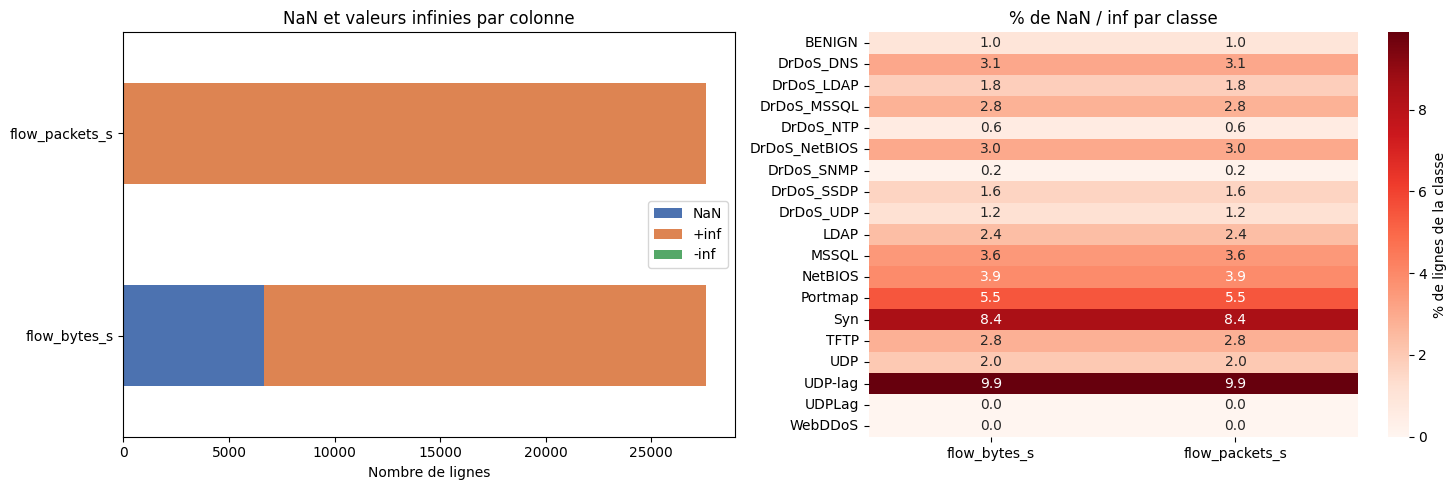

                avant  lignes_pb   % perdu
label                                     
UDP-lag         49880     4935.0  9.893745
Syn             50371     4252.0  8.441365
Portmap         50174     2753.0  5.486906
NetBIOS         50209     1966.0  3.915633
MSSQL           49796     1769.0  3.552494
DrDoS_DNS       49916     1536.0  3.077170
DrDoS_NetBIOS   49939     1519.0  3.041711
TFTP            50402     1415.0  2.807428
DrDoS_MSSQL     50152     1387.0  2.765593
LDAP            50135     1182.0  2.357634
UDP             49704     1012.0  2.036053
DrDoS_LDAP      49928      914.0  1.830636
DrDoS_SSDP      50112      824.0  1.644317
DrDoS_UDP       50068      612.0  1.222338
BENIGN         113828     1097.0  0.963735
DrDoS_NTP       49866      297.0  0.595596
DrDoS_SNMP      49977      111.0  0.222102
UDPLag           1873        0.0  0.000000
WebDDoS           439        0.0  0.000000


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Barres empilées par colonne
diag_pb[["NaN", "+inf", "-inf"]].plot(kind="barh", stacked=True, ax=axes[0],
                                      color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("NaN et valeurs infinies par colonne")
axes[0].set_xlabel("Nombre de lignes")

# (b) Carte de chaleur : % de lignes problématiques par classe et par colonne
pb = df[diag_pb.index].isna() | np.isinf(df[diag_pb.index])
heat = 100 * pb.groupby(df["label"]).mean()
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", ax=axes[1],
            cbar_kws={"label": "% de lignes de la classe"})
axes[1].set_title("% de NaN / inf par classe")
axes[1].set_xlabel(""); axes[1].set_ylabel("")

plt.tight_layout(); plt.show()

# Effet d'une suppression sur chaque classe
perte = pd.DataFrame({"avant": df["label"].value_counts(),
                      "lignes_pb": df.loc[lignes_pb, "label"].value_counts()}).fillna(0)
perte["% perdu"] = 100 * perte["lignes_pb"] / perte["avant"]
print(perte.sort_values("% perdu", ascending=False))

In [20]:
avant = df.shape

# Stratégie retenue : suppression des lignes concernées
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna().reset_index(drop=True)

print(f"Taille : {avant} -> {df.shape}  ({avant[0]-df.shape[0]:,} lignes supprimées)")
print("NaN restants :", df.isna().sum().sum(),
      "| inf restants :", np.isinf(df.select_dtypes('number')).sum().sum())

Taille : (916769, 74) -> (889188, 74)  (27,581 lignes supprimées)
NaN restants : 0 | inf restants : 0


**Résultat :** seules **2 colonnes** sont touchées : `flow_bytes_s` (6 653 NaN + 20 928 +inf) et `flow_packets_s` (27 581 +inf). Aucune valeur −inf. Au total, **27 581 lignes** sont concernées, soit **3,01 %** du jeu, et **100 %** d'entre elles ont `flow_duration = 0`. Cela confirme la division par zéro de CICFlowMeter : 0/0 donne NaN, x/0 donne +inf.

**Stratégie retenue : suppression des lignes.** Le jeu passe de 916 769 à **889 188 lignes**, sans aucun NaN ni inf restant.

- **Volume faible :** on perd 3 % des lignes. Les classes les plus touchées sont UDP-lag (**9,9 %**), Syn (8,4 %) et Portmap (5,5 %). Ce sont des attaques qui envoient beaucoup de flux d'un seul paquet. Elles gardent toutes plus de 45 000 exemples, ce qui reste suffisant. Les classes rares **UDPLag et WebDDoS ne perdent aucune ligne (0 %)**, et BENIGN seulement 0,96 %.
- **Valeurs non mesurées :** un débit « infini » n'a pas de sens physique. Le remplacer par une valeur inventée ajouterait du bruit.
- **Pourquoi pas la médiane :** une imputation correcte devrait être calculée **sur le train seulement** (Q13), sinon le test influencerait la valeur imputée (fuite). Elle remplacerait aussi des débits extrêmes par une valeur « typique », ce qui fausserait les flux d'attaque très courts.
- **Alternative possible :** remplacer +inf par le maximum fini de la colonne garderait l'idée de « débit très élevé ». Comme UDP-lag et Syn sont les plus touchées, cette option reste défendable. On a préféré la suppression, plus simple et sans risque de fuite, puisque les pertes restent sous 10 % par classe.

### Question 7 — Doublons (2 pts)

**Énoncé :** Compter les lignes dupliquées, les supprimer, vérifier la nouvelle taille et présenter un tableau avant/après par classe. Commenter : quelles classes perdent le plus de lignes et pourquoi ?

**Démarche :** une ligne est un doublon si **toutes** ses valeurs (les 73 features et le label) sont identiques à celles d'une autre ligne. On garde la première occurrence (`keep="first"`). On compte aussi les flux identiques qui portent des labels **différents** : ils sont impossibles à séparer pour un modèle.

**Pourquoi supprimer les doublons :**

- ils surpondèrent artificiellement certains motifs, et le modèle les « apprend par cœur » ;
- après le découpage train/test (Q13), une même ligne pourrait se retrouver dans les deux ensembles. Le modèle serait alors évalué sur des exemples qu'il a déjà vus, ce qui gonfle les scores (fuite de données).

Lignes dupliquées : 578,126 sur 889,188 (65.02 %)
Groupes de flux identiques portant des labels différents : 11,750
Taille : (889188, 74) -> (311062, 74)  (578,126 lignes supprimées)
                avant  après  supprimées  % perdu
label                                            
Portmap         47421    771       46650     98.4
NetBIOS         48243    799       47444     98.3
DrDoS_NetBIOS   48420   1222       47198     97.5
LDAP            48953   2097       46856     95.7
DrDoS_LDAP      49014   3213       45801     93.4
DrDoS_DNS       48380   5240       43140     89.2
DrDoS_SNMP      49866   6029       43837     87.9
Syn             46119   8215       37904     82.2
UDPLag           1873    455        1418     75.7
DrDoS_MSSQL     48765  11977       36788     75.4
MSSQL           48027  13074       34953     72.8
UDP-lag         44945  13143       31802     70.8
TFTP            48987  25128       23859     48.7
DrDoS_UDP       49456  25586       23870     48.3
DrDoS_SSDP      4

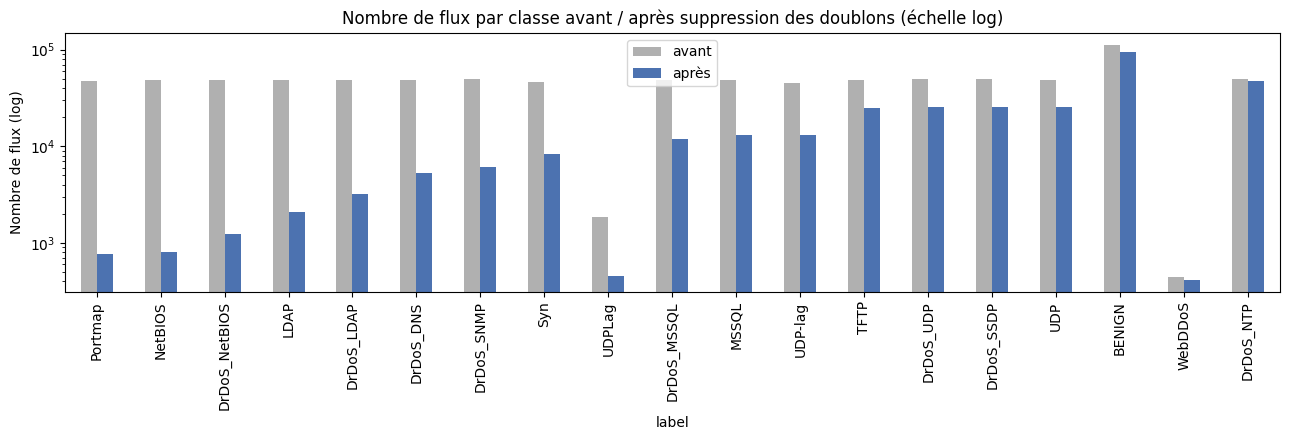

In [21]:
# --- 1) Doublons exacts (toutes les colonnes, label compris) ---
avant = df.shape
n_avant = df["label"].value_counts()

dup = df.duplicated(keep="first")
print(f"Lignes dupliquées : {dup.sum():,} sur {len(df):,} ({100*dup.mean():.2f} %)")

# --- 2) Doublons « ambigus » : mêmes features, labels différents ---
features = [c for c in df.columns if c != "label"]
memes_features = df.duplicated(subset=features, keep=False)
ambigus = df[memes_features].groupby(features, sort=False)["label"].nunique()
n_ambigus = int((ambigus > 1).sum())
print(f"Groupes de flux identiques portant des labels différents : {n_ambigus:,}")

# --- 3) Suppression ---
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Taille : {avant} -> {df.shape}  ({avant[0]-df.shape[0]:,} lignes supprimées)")
assert df.duplicated().sum() == 0

# --- 4) Tableau avant / après par classe ---
tab = pd.DataFrame({"avant": n_avant, "après": df["label"].value_counts()}).fillna(0).astype(int)
tab["supprimées"] = tab["avant"] - tab["après"]
tab["% perdu"] = (100 * tab["supprimées"] / tab["avant"]).round(1)
tab = tab.sort_values("% perdu", ascending=False)
print(tab.to_string())

# --- 5) Graphique ---
ax = tab[["avant", "après"]].plot(kind="bar", figsize=(13, 4.5), logy=True,
                                  color=["#B0B0B0", "#4C72B0"])
ax.set_title("Nombre de flux par classe avant / après suppression des doublons (échelle log)")
ax.set_ylabel("Nombre de flux (log)")
plt.tight_layout(); plt.show()

**Résultat :** **578 126 lignes dupliquées** sur 889 188, soit **65 %** de l'échantillon. Après suppression, le jeu passe de **889 188 × 74 à 311 062 × 74** (vérification : 0 doublon restant).

| Classe | Avant | Après | % perdu |
|---|---:|---:|---:|
| Portmap | 47 421 | 771 | **98,4** |
| NetBIOS | 48 243 | 799 | **98,3** |
| DrDoS_NetBIOS | 48 420 | 1 222 | **97,5** |
| LDAP | 48 953 | 2 097 | 95,7 |
| DrDoS_LDAP | 49 014 | 3 213 | 93,4 |
| DrDoS_DNS | 48 380 | 5 240 | 89,2 |
| DrDoS_SNMP | 49 866 | 6 029 | 87,9 |
| Syn | 46 119 | 8 215 | 82,2 |
| UDPLag | 1 873 | 455 | 75,7 |
| DrDoS_MSSQL | 48 765 | 11 977 | 75,4 |
| MSSQL | 48 027 | 13 074 | 72,8 |
| UDP-lag | 44 945 | 13 143 | 70,8 |
| TFTP | 48 987 | 25 128 | 48,7 |
| DrDoS_UDP | 49 456 | 25 586 | 48,3 |
| DrDoS_SSDP | 49 288 | 25 675 | 47,9 |
| UDP | 48 692 | 25 627 | 47,4 |
| BENIGN | 112 731 | 95 315 | 15,4 |
| WebDDoS | 439 | 414 | 5,7 |
| DrDoS_NTP | 49 569 | 47 082 | 5,0 |

**Quelles classes perdent le plus, et pourquoi ?**

- **Les attaques par réflexion à paquets fixes** (Portmap, NetBIOS, LDAP, DNS, SNMP : 88 à 98 % de pertes). L'outil d'attaque envoie des millions de requêtes **identiques** (même taille de paquet, même protocole, un seul paquet par flux, durée quasi nulle). Une fois les IP, ports et horodatages retirés en Q5, ces flux deviennent **strictement identiques** ligne à ligne. Ils n'apportent donc qu'une poignée de motifs distincts.
- **Syn, MSSQL, UDP-lag (70 à 82 %)** : des inondations de paquets de taille fixe, avec un peu plus de variabilité.
- **TFTP, SSDP, UDP (≈ 48 %)** : les tailles de réponse et les temps inter-arrivées varient davantage.
- **BENIGN (15 %), WebDDoS (6 %), NTP (5 %)** perdent peu : le trafic normal (HTTP, SSH, e-mail…) et les réponses NTP *monlist* ont des tailles et des durées très variables, donc presque tous les flux sont uniques.

**Flux ambigus :** **11 750 groupes** de flux ont exactement les mêmes features mais des labels différents. Ce sont surtout des attaques du même type enregistrées sous deux noms selon le jour (ex. NetBIOS / DrDoS_NetBIOS / Portmap, LDAP / DrDoS_LDAP). Aucun modèle ne peut les distinguer en multiclasse. Le regroupement par familles en Q15 (Reflection / Exploitation) atténuera ce problème.

**Conséquence :** la suppression des doublons rend le jeu beaucoup plus petit, mais plus honnête : sans elle, une même ligne se retrouverait à la fois dans le train et dans le test (Q13), ce qui gonflerait artificiellement les scores. En contrepartie, certaines classes deviennent très petites (Portmap : 771, NetBIOS : 799, UDPLag : 455, WebDDoS : 414). Ce déséquilibre sera traité en Q14.

### Question 8 — Colonnes constantes ou quasi constantes (2 pts)

**Énoncé :** Les détecter avec `nunique()` ou `VarianceThreshold`, lister celles supprimées et expliquer pourquoi elles n'apportent aucune information.

**Démarche :**

- **Constante :** la colonne ne prend qu'une seule valeur sur tout le jeu (`nunique() == 1`). On le vérifie aussi avec `VarianceThreshold(threshold=0)`, qui retire les colonnes de variance nulle. Les deux méthodes doivent donner la même liste.
- **Quasi constante :** une même valeur occupe au moins **99,9 %** des lignes. Pour ne pas jeter une information utile à une classe rare, on regarde à quelles classes appartiennent les quelques lignes qui ont une autre valeur.

In [22]:
from sklearn.feature_selection import VarianceThreshold

X_num = df.drop(columns="label").select_dtypes("number")
avant = df.shape

# --- 1) Colonnes CONSTANTES : une seule valeur (nunique == 1) ---
nuniq = X_num.nunique()
constantes = nuniq[nuniq == 1].index.tolist()

# Vérification croisée avec VarianceThreshold(seuil = 0)
vt = VarianceThreshold(threshold=0.0).fit(X_num)
constantes_vt = X_num.columns[~vt.get_support()].tolist()
assert set(constantes) == set(constantes_vt)
print(f"{len(constantes)} colonnes constantes :")
print(pd.DataFrame({"valeur unique": X_num[constantes].iloc[0]}).to_string())

# --- 2) Colonnes QUASI CONSTANTES : valeur dominante >= 99,9 % des lignes ---
SEUIL = 0.999
part_dom = X_num.apply(lambda s: s.value_counts(normalize=True).iat[0])
quasi = part_dom[(part_dom >= SEUIL) & (nuniq > 1)].sort_values(ascending=False)

# Les rares valeurs non dominantes sont-elles liées à une classe ? (sinon : bruit)
lignes = []
for c in quasi.index:
    dom = X_num[c].value_counts().index[0]
    rares = df.loc[X_num[c] != dom, "label"].value_counts()
    lignes.append({"colonne": c, "% dominante": round(100*quasi[c], 3),
                   "nb lignes ≠": int(rares.sum()),
                   "classe principale des ≠": rares.index[0],
                   "part de cette classe": f"{100*rares.iat[0]/rares.sum():.0f} %"})
tab_quasi = pd.DataFrame(lignes)
print(f"\n{len(quasi)} colonnes quasi constantes (≥ {100*SEUIL:.1f} %) :")
print(tab_quasi.to_string(index=False))

# --- 3) Suppression ---
a_supprimer = constantes + quasi.index.tolist()
df = df.drop(columns=a_supprimer)
print(f"\nColonnes supprimées ({len(a_supprimer)}) : {a_supprimer}")
print(f"Taille : {avant} -> {df.shape}")

12 colonnes constantes :
                      valeur unique
bwd_psh_flags                     0
fwd_urg_flags                     0
bwd_urg_flags                     0
fin_flag_count                    0
psh_flag_count                    0
ece_flag_count                    0
fwd_avg_bytes_bulk                0
fwd_avg_packets_bulk              0
fwd_avg_bulk_rate                 0
bwd_avg_bytes_bulk                0
bwd_avg_packets_bulk              0
bwd_avg_bulk_rate                 0

1 colonnes quasi constantes (≥ 99.9 %) :
       colonne  % dominante  nb lignes ≠ classe principale des ≠ part de cette classe
syn_flag_count       99.943          177                  BENIGN                 94 %

Colonnes supprimées (13) : ['bwd_psh_flags', 'fwd_urg_flags', 'bwd_urg_flags', 'fin_flag_count', 'psh_flag_count', 'ece_flag_count', 'fwd_avg_bytes_bulk', 'fwd_avg_packets_bulk', 'fwd_avg_bulk_rate', 'bwd_avg_bytes_bulk', 'bwd_avg_packets_bulk', 'bwd_avg_bulk_rate', 'syn_flag_count']
Taille 

**Résultat :** **13 colonnes supprimées**, et le jeu passe de **311 062 × 74 à 311 062 × 61** (60 features + `label`).

**12 colonnes constantes**, toujours égales à 0. `nunique()` et `VarianceThreshold(0)` donnent la même liste :

| Groupe | Colonnes |
|---|---|
| Drapeaux TCP jamais activés | `bwd_psh_flags`, `fwd_urg_flags`, `bwd_urg_flags`, `fin_flag_count`, `psh_flag_count`, `ece_flag_count` |
| Statistiques « bulk » | `fwd_avg_bytes_bulk`, `fwd_avg_packets_bulk`, `fwd_avg_bulk_rate`, `bwd_avg_bytes_bulk`, `bwd_avg_packets_bulk`, `bwd_avg_bulk_rate` |

**1 colonne quasi constante :** `syn_flag_count` vaut 0 dans **99,94 %** des lignes. Seuls 177 flux ont une autre valeur, et 94 % d'entre eux sont BENIGN. Elle ne permet donc de distinguer aucune attaque, pas même Syn, alors que c'est précisément l'attaque par drapeau SYN : CICFlowMeter ne compte visiblement pas ce drapeau de façon fiable dans ce jeu.

**Pourquoi ces colonnes n'apportent aucune information :**

- Une colonne constante a la **même valeur pour toutes les classes**. Elle ne peut donc séparer aucune classe d'une autre (variance nulle, information mutuelle nulle avec le label).
- Les statistiques *bulk* ne sont calculées par CICFlowMeter que pour des transferts en rafale, absents ici. Les drapeaux URG, ECE, FIN, PSH ne sont jamais positionnés, ou ne sont pas comptés par l'outil.
- Les garder serait pénalisant : elles alourdissent la mémoire et le temps de calcul, provoquent des divisions par zéro lors de la normalisation (écart-type nul pour `StandardScaler`, Q12), et produisent des corrélations indéfinies (NaN) dans la matrice de Pearson (Q10).
- Pour la colonne quasi constante, 177 lignes sur 311 062 (0,06 %) ne suffisent pas à apprendre une règle fiable : c'est surtout du bruit.

### Question 9 — Valeurs aberrantes (2 pts)

**Énoncé :** Tracer des boîtes à moustaches pour au moins 5 features, appliquer la méthode IQR pour les compter. Discuter : dans un IDS, faut-il supprimer les valeurs aberrantes, sachant qu'une attaque est elle-même un comportement anormal ?

**Méthode IQR :** pour chaque feature, on calcule Q1 (25 %), Q3 (75 %) et l'écart interquartile IQR = Q3 − Q1. Une valeur est dite aberrante si elle sort de l'intervalle [Q1 − 1,5·IQR ; Q3 + 1,5·IQR].

On étudie **8 features** représentatives : durée (`flow_duration`), débits (`flow_bytes_s`, `flow_packets_s`), volumes (`total_fwd_packets`), tailles de paquets (`fwd_packet_length_max`, `packet_length_mean`), temps inter-arrivées (`flow_iat_mean`) et fenêtre TCP initiale (`init_win_bytes_forward`). Les valeurs couvrent plusieurs ordres de grandeur, donc les boîtes sont tracées en échelle `log1p` pour rester lisibles. Le comptage IQR, lui, est fait sur les valeurs brutes.

                          Q1           Q3   borne basse  borne haute  nb aberrantes  % lignes
feature                                                                                      
flow_duration          279.0    216,597.0    -324,198.0    541,074.0          63261      20.3
flow_bytes_s           787.4 11,499,625.8 -17,247,470.2 28,747,883.3          57327      18.4
flow_packets_s          27.8     40,000.0     -59,930.5     99,958.3          53976      17.4
total_fwd_packets        2.0          6.0          -4.0         12.0          58662      18.9
fwd_packet_length_max   42.0        440.0        -555.0      1,037.0          19731       6.3
packet_length_mean      54.2        440.0        -524.5      1,018.7          16334       5.3
flow_iat_mean           46.0     43,227.2     -64,725.8    107,999.0          59346      19.1
init_win_bytes_forward  -1.0         -1.0          -1.0         -1.0          76970      24.7

Lignes aberrantes sur au moins une de ces 8 features : 188,

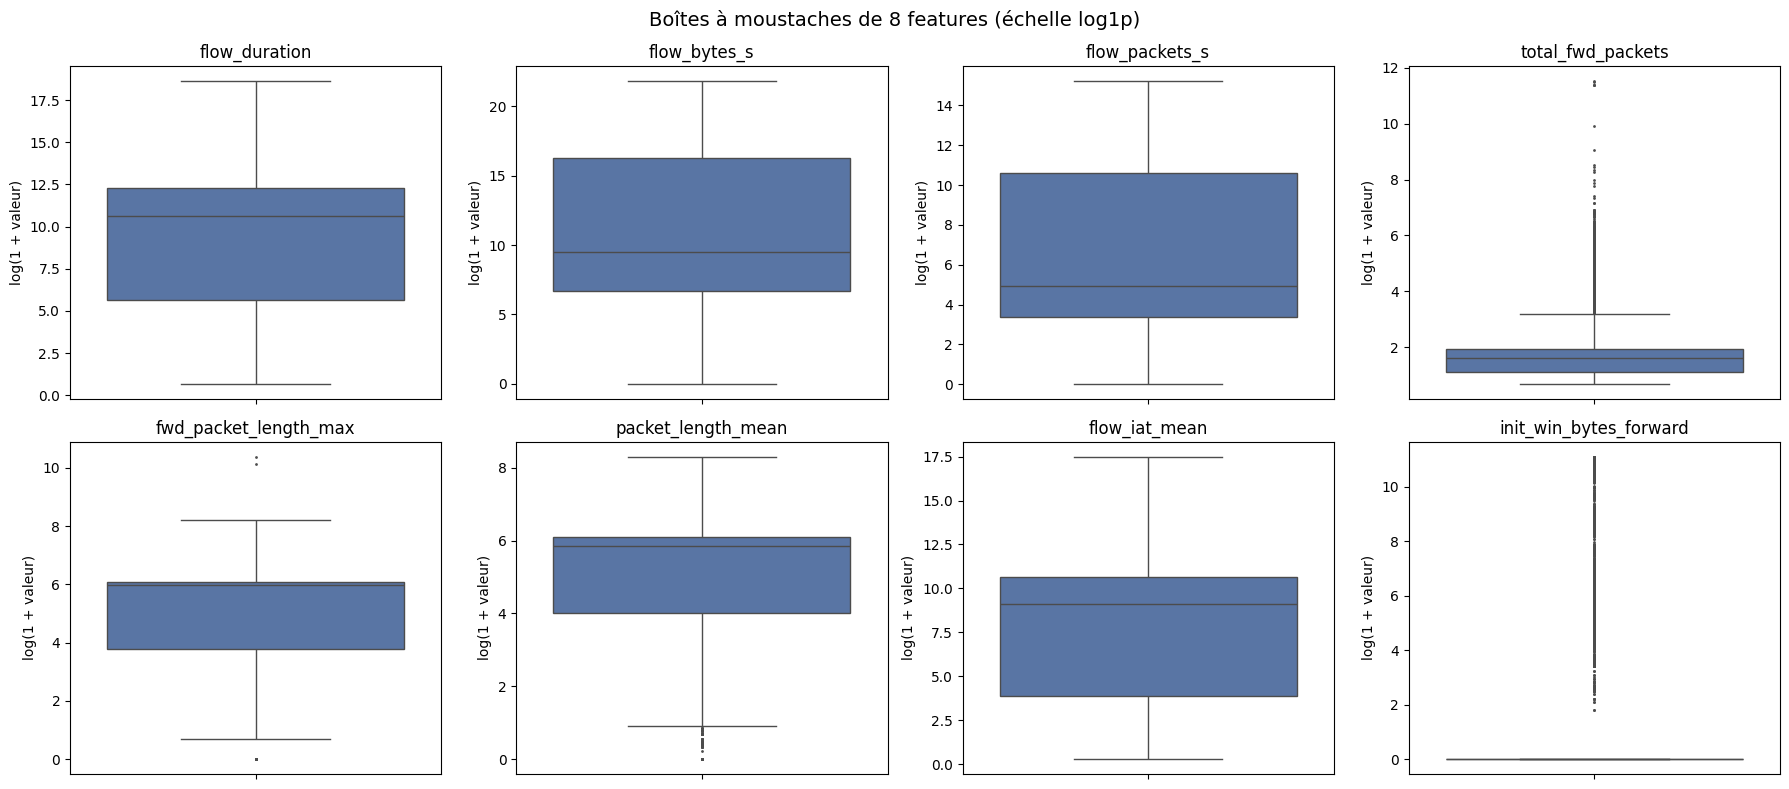

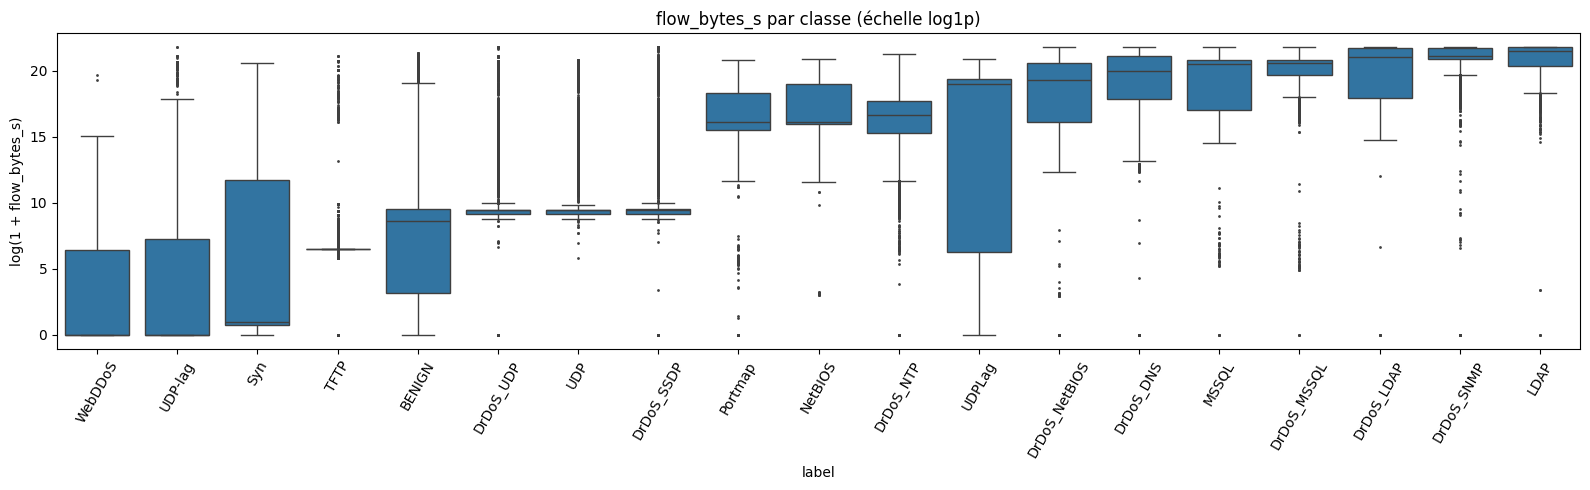


Aucune ligne supprimée : taille inchangée (311062, 61)


In [23]:
# --- Features étudiées (débits, durées, tailles, compteurs) ---
FEATS = ["flow_duration", "flow_bytes_s", "flow_packets_s", "total_fwd_packets",
         "fwd_packet_length_max", "packet_length_mean", "flow_iat_mean", "init_win_bytes_forward"]

# --- 1) Comptage des valeurs aberrantes par la méthode IQR ---
def bornes_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lignes, masque_global = [], pd.Series(False, index=df.index)
for c in FEATS:
    bas, haut = bornes_iqr(df[c])
    m = (df[c] < bas) | (df[c] > haut)
    masque_global |= m
    lignes.append({"feature": c, "Q1": df[c].quantile(.25), "Q3": df[c].quantile(.75),
                   "borne basse": bas, "borne haute": haut,
                   "nb aberrantes": int(m.sum()), "% lignes": round(100 * m.mean(), 1)})
tab_iqr = pd.DataFrame(lignes).set_index("feature")
pd.set_option("display.float_format", "{:,.1f}".format)
print(tab_iqr.to_string())
print(f"\nLignes aberrantes sur au moins une de ces {len(FEATS)} features : "
      f"{masque_global.sum():,} ({100*masque_global.mean():.1f} % du jeu)")

# --- 2) Part de lignes « aberrantes » par classe ---
part = (100 * masque_global.groupby(df["label"]).mean()).sort_values(ascending=False).round(1)
print("\n% de lignes aberrantes par classe :")
print(part.to_string())

# --- 3) Boîtes à moustaches ---
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), FEATS):
    sns.boxplot(y=np.log1p(df[c].clip(lower=0)), ax=ax, color="#4C72B0", fliersize=1)
    ax.set_title(c); ax.set_ylabel("log(1 + valeur)")
fig.suptitle("Boîtes à moustaches de 8 features (échelle log1p)", fontsize=14)
plt.tight_layout(); plt.show()

# --- 4) Une feature par classe : les « aberrations » sont la signature des attaques ---
plt.figure(figsize=(16, 5))
ordre = df.groupby("label")["flow_bytes_s"].median().sort_values().index
sns.boxplot(data=df.assign(log_fbs=np.log1p(df["flow_bytes_s"].clip(lower=0))),
            x="label", y="log_fbs", order=ordre, fliersize=1)
plt.xticks(rotation=60); plt.ylabel("log(1 + flow_bytes_s)")
plt.title("flow_bytes_s par classe (échelle log1p)")
plt.tight_layout(); plt.show()

print(f"\nAucune ligne supprimée : taille inchangée {df.shape}")

**Résultat du comptage IQR :**

| Feature | Q1 | Q3 | Borne haute | Nb aberrantes | % lignes |
|---|---:|---:|---:|---:|---:|
| `flow_duration` (µs) | 279 | 216 597 | 541 074 | 63 261 | 20,3 |
| `flow_bytes_s` | 787 | 11 499 626 | 28 747 883 | 57 327 | 18,4 |
| `flow_packets_s` | 28 | 40 000 | 99 958 | 53 976 | 17,4 |
| `total_fwd_packets` | 2 | 6 | 12 | 58 662 | 18,9 |
| `fwd_packet_length_max` | 42 | 440 | 1 037 | 19 731 | 6,3 |
| `packet_length_mean` | 54 | 440 | 1 019 | 16 334 | 5,3 |
| `flow_iat_mean` (µs) | 46 | 43 227 | 107 999 | 59 346 | 19,1 |
| `init_win_bytes_forward` | −1 | −1 | −1 | 76 970 | 24,7 |

Au total, **188 382 lignes (60,6 % du jeu)** sont aberrantes sur au moins une de ces 8 features. Les boîtes à moustaches confirment des distributions très asymétriques, étalées sur plusieurs ordres de grandeur.

Pour `init_win_bytes_forward`, Q1 = Q3 = −1 : CICFlowMeter met −1 quand il n'y a pas de poignée de main TCP (flux UDP, majoritaires ici). L'IQR vaut donc 0, et **toute** vraie fenêtre TCP est déclarée « aberrante ». Cela montre les limites de la méthode IQR sur ce type de données.

**Par classe :** la part de lignes aberrantes atteint **100 % pour WebDDoS et Syn**, et plus de 95 % pour LDAP, TFTP, SNMP et DNS. Elle tombe à environ 8 à 11 % pour UDP, DrDoS_UDP et SSDP. Le trafic **BENIGN** est lui-même « aberrant » à 63 %. Le graphique `flow_bytes_s` par classe montre que chaque attaque occupe sa propre plage de débits.

**Discussion : faut-il supprimer les valeurs aberrantes dans un IDS ? Non.**

1. **L'anomalie est le signal à détecter.** Une attaque DDoS se caractérise justement par des débits, des volumes ou des durées extrêmes. Supprimer les lignes « aberrantes » reviendrait à supprimer les attaques : on perdrait ici 60 % du jeu, et 100 % des classes WebDDoS et Syn.
2. **L'IQR suppose une distribution unimodale proche de la normale.** Le jeu mélange 19 classes aux comportements très différents. Une valeur aberrante pour l'ensemble est souvent parfaitement normale *pour sa classe*.
3. **Ces valeurs ne sont pas des erreurs de mesure.** Les vraies erreurs (NaN, ±inf venant des divisions par zéro) ont déjà été traitées en Q6.
4. **Biais en production :** un modèle entraîné sans les extrêmes ne reconnaîtrait pas une attaque massive le jour où elle se produit.

**Décision :** on **conserve toutes les lignes** (taille inchangée : 311 062 × 61). L'effet des extrêmes est géré autrement :

- par une transformation `log1p` et un **`RobustScaler`** (basé sur la médiane et l'IQR, peu sensible aux extrêmes) en Q12 ;
- éventuellement par des modèles robustes aux valeurs extrêmes (arbres, forêts aléatoires).

## Partie D — Transformation (11 pts)
### Question 10 — Corrélation et sélection de features (2 pts)

**Énoncé :** Tracer la matrice de corrélation (Pearson), supprimer une feature de chaque paire avec |r| > 0,95 et afficher la liste retirée ainsi que le nombre de features restantes.

**Démarche :**

- On calcule la corrélation de Pearson entre toutes les features numériques. `protocol` est exclue : c'est une variable catégorielle (6 = TCP, 17 = UDP) qui sera encodée en Q11, et un coefficient linéaire n'a pas de sens pour elle.
- On parcourt le **triangle supérieur** de la matrice, pour ne compter chaque paire qu'une fois. Pour chaque paire avec |r| > 0,95, on retire la feature qui apparaît **en second** dans l'ordre des colonnes, et on garde la première.
- **Pourquoi :** deux features presque parfaitement corrélées portent la même information. En garder une seule réduit la dimension et le temps de calcul, évite la **multicolinéarité** (coefficients instables pour la régression logistique, importance « diluée » entre copies pour les forêts) et limite le sur-apprentissage.

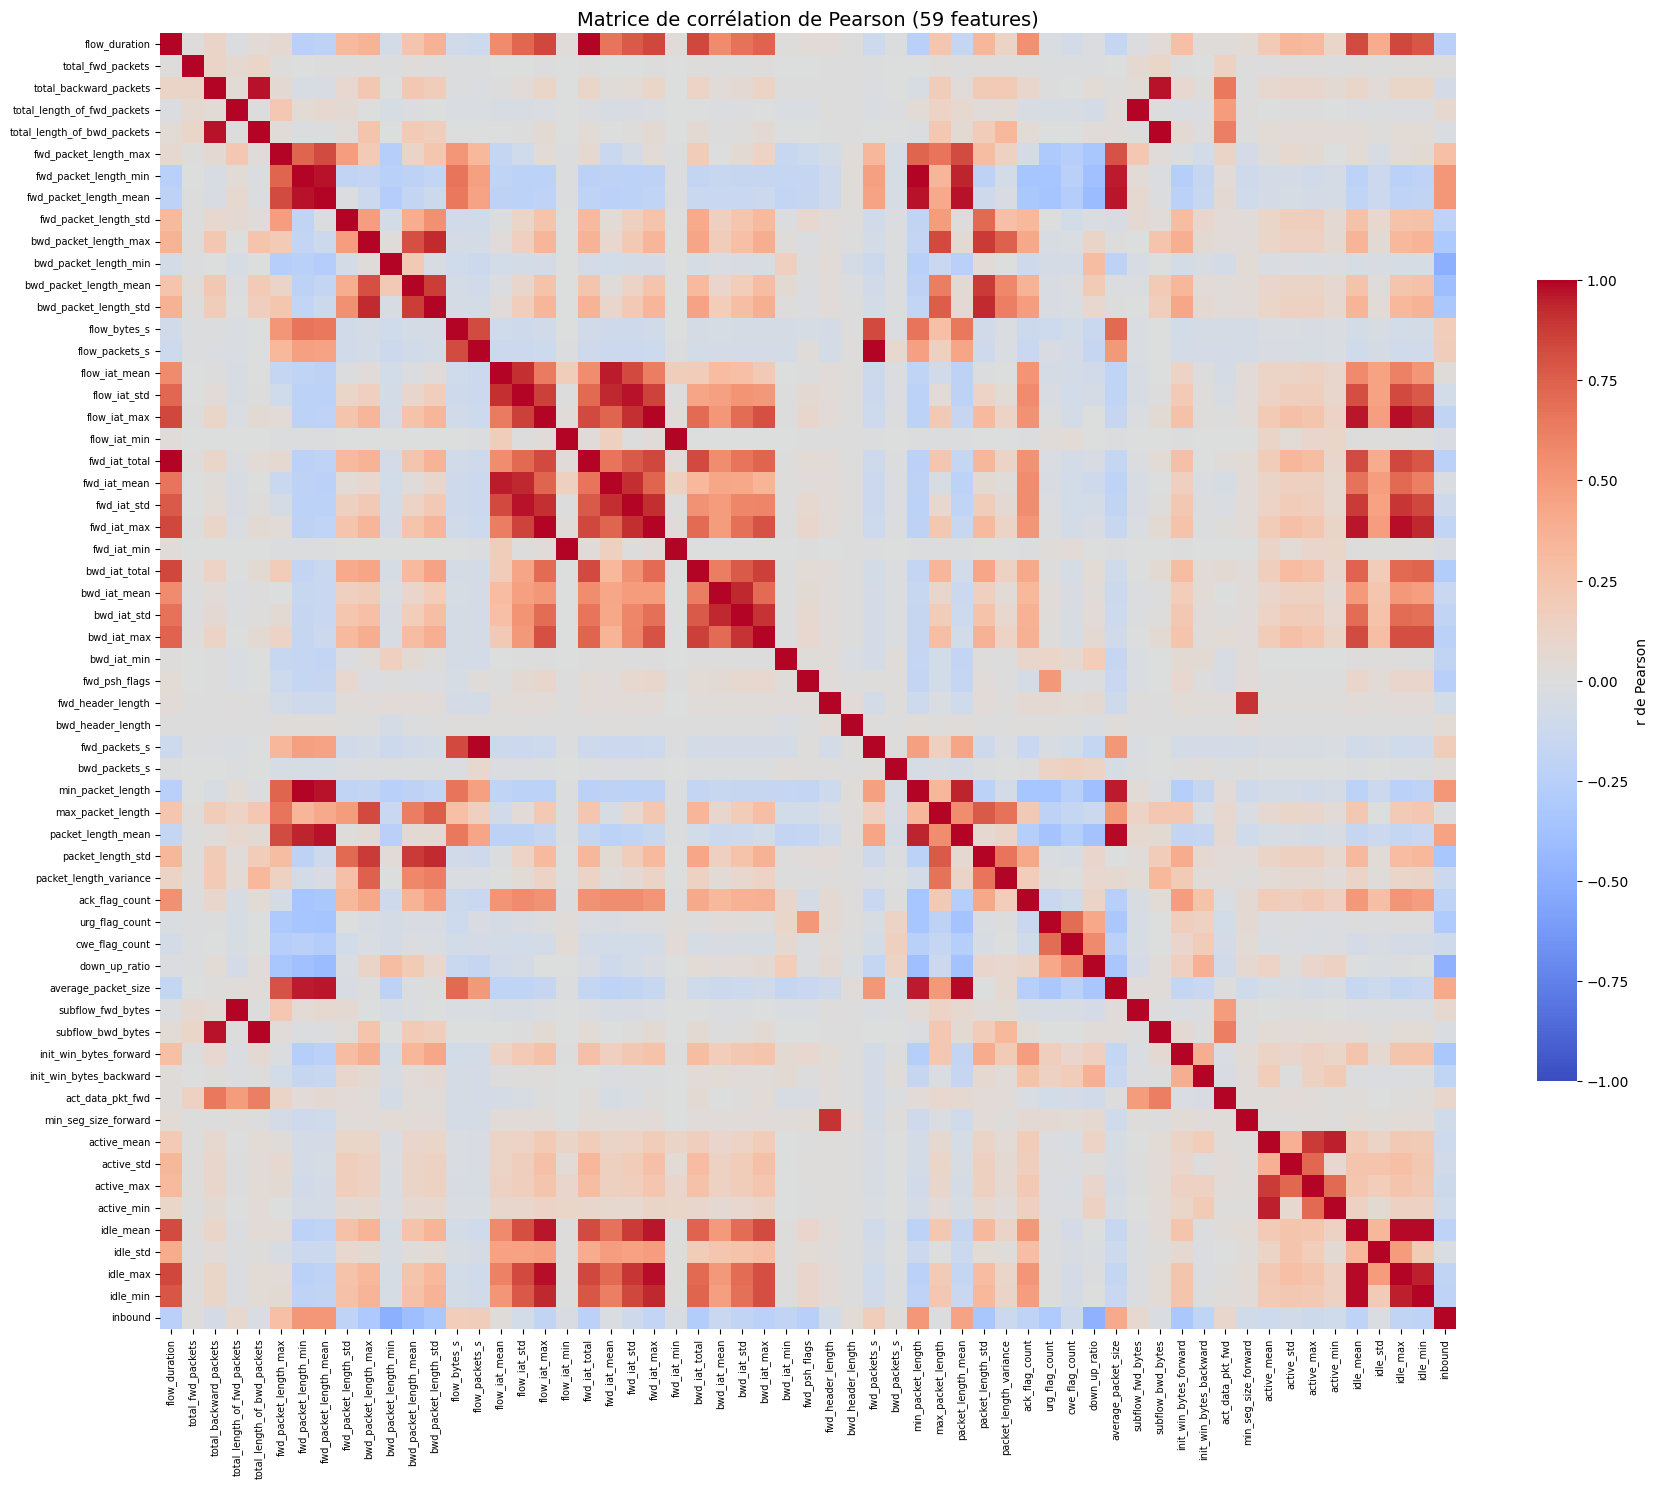

25 paires avec |r| > 0.95 :
feature A (gardée si possible)                   feature B   |r|
   total_length_of_bwd_packets           subflow_bwd_bytes 1.000
   total_length_of_fwd_packets           subflow_fwd_bytes 1.000
                 flow_duration               fwd_iat_total 0.998
                flow_packets_s               fwd_packets_s 0.998
         fwd_packet_length_min           min_packet_length 0.997
                  flow_iat_min                 fwd_iat_min 0.995
                  flow_iat_max                 fwd_iat_max 0.995
                     idle_mean                    idle_min 0.988
                     idle_mean                    idle_max 0.986
            packet_length_mean         average_packet_size 0.986
                   fwd_iat_max                    idle_max 0.981
                  flow_iat_max                    idle_max 0.980
         fwd_packet_length_min      fwd_packet_length_mean 0.976
                  flow_iat_std                 fwd_iat_std 0.9

In [24]:
# Features numériques continues (protocol est catégorielle : elle sera encodée en Q11)
feat_corr = [c for c in df.select_dtypes("number").columns if c not in ("protocol",)]
avant = df.shape

# --- 1) Matrice de corrélation de Pearson ---
corr = df[feat_corr].corr(method="pearson")

plt.figure(figsize=(18, 15))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": .6, "label": "r de Pearson"})
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
plt.title(f"Matrice de corrélation de Pearson ({len(feat_corr)} features)", fontsize=14)
plt.tight_layout(); plt.show()

# --- 2) Paires très corrélées (|r| > 0,95) ---
SEUIL = 0.95
haut = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))   # triangle supérieur
paires = (haut.stack().loc[lambda s: s > SEUIL]
              .sort_values(ascending=False).rename("|r|").reset_index()
              .rename(columns={"level_0": "feature A (gardée si possible)", "level_1": "feature B"}))
print(f"{len(paires)} paires avec |r| > {SEUIL} :")
print(paires.to_string(index=False, float_format="{:.3f}".format))

# --- 3) Suppression : pour chaque paire, on retire la feature qui arrive en second ---
a_retirer = [c for c in haut.columns if (haut[c] > SEUIL).any()]
df = df.drop(columns=a_retirer)

print(f"\n{len(a_retirer)} features retirées : {a_retirer}")
print(f"Taille : {avant} -> {df.shape}")
print(f"Features restantes (hors label) : {df.shape[1] - 1}")

**Résultat :** la matrice montre plusieurs **blocs rouges** de features quasi identiques : temps inter-arrivées (`flow_iat_*`, `fwd_iat_*`, `idle_*`), tailles de paquets (`*_packet_length_*`, `average_packet_size`) et volumes (`total_*`, `subflow_*`). On trouve **25 paires avec |r| > 0,95**, dont deux à r = 1,000.

**16 features retirées**, et le jeu passe de **311 062 × 61 à 311 062 × 45**, soit **44 features restantes** plus le label :

| Feature retirée | Corrélée à (gardée) | \|r\| | Explication |
|---|---|---:|---|
| `subflow_fwd_bytes` | `total_length_of_fwd_packets` | 1,000 | Un seul sous-flux par flux : mêmes octets |
| `subflow_bwd_bytes` | `total_backward_packets` | 0,974 | Idem pour le sens retour |
| `total_length_of_bwd_packets` | `total_backward_packets` | 0,974 | Nb de paquets × taille quasi fixe |
| `fwd_iat_total` | `flow_duration` | 0,998 | Durée ≈ somme des inter-arrivées aller |
| `fwd_packets_s` | `flow_packets_s` | 0,998 | Presque tout le trafic est dans le sens aller |
| `fwd_iat_mean`, `fwd_iat_std`, `fwd_iat_min`, `fwd_iat_max` | `flow_iat_mean`, `flow_iat_std`, `flow_iat_min`, `flow_iat_max` | 0,957 à 0,995 | Même raison : flux surtout unidirectionnels |
| `idle_mean`, `idle_max` | `flow_iat_max` | 0,966 à 0,981 | Une période d'inactivité = le plus grand écart entre paquets |
| `idle_min` | `idle_mean`, `idle_max` (retirées elles aussi) | 0,950 à 0,988 | Même groupe *idle* |
| `min_packet_length`, `fwd_packet_length_mean` | `fwd_packet_length_min` | 0,973 à 0,997 | Attaques à paquets de taille fixe : min ≈ moyenne |
| `average_packet_size` | `fwd_packet_length_min` | 0,959 | Même information de taille moyenne |
| `packet_length_mean` | `average_packet_size`, `fwd_packet_length_mean` (retirées elles aussi) | 0,969 à 0,986 | Même groupe de tailles |

**Commentaire :**

- Ces redondances viennent de la **construction des features par CICFlowMeter** : plusieurs statistiques mesurent la même chose sous des noms différents (aller / flux total, *subflow* / total, *idle* / IAT max). Elles sont renforcées par la nature des attaques DDoS, qui envoient des flux unidirectionnels de paquets de taille fixe.
- Chaque bloc garde au moins **un représentant** (`flow_duration`, `flow_packets_s`, `flow_iat_*`, `fwd_packet_length_min`, `total_*`…). On passe de 60 à 44 features (−27 %) presque sans perte d'information.
- **Effet de chaîne :** la règle « retirer la seconde de chaque paire » peut retirer une feature dont le partenaire a lui-même été retiré (ex. `idle_min` ou `packet_length_mean`). L'information reste couverte par le bloc (`flow_iat_max`, `fwd_packet_length_min`), mais pas toujours avec |r| > 0,95.
- **Limite :** la corrélation de Pearson ne mesure que les liens **linéaires**, et elle est sensible aux valeurs extrêmes (Q9). Deux features liées de façon non linéaire sont conservées. Une corrélation de Spearman ou une sélection basée sur un modèle (importance d'une forêt aléatoire) serait un complément possible.
- **Remarque sur la fuite :** la sélection est faite ici sur tout l'échantillon, avant le découpage de la Q13, comme le demande l'ordre du TP. Elle n'utilise pas le label, donc le risque de fuite est faible. Dans un pipeline strict (Q16), cette étape serait ajustée sur le train seulement.

### Question 11 — Encodage (3 pts)

**Énoncé :** Créer deux cibles — binaire (BENIGN = 0, attaque = 1) et multiclasse. Encoder les variables catégorielles restantes (ex. Protocol). Justifier le choix LabelEncoder vs One-Hot vs ColumnTransformer, en tenant compte de l'absence d'ordre entre les modalités.

**Démarche :**

1. **Harmonisation des labels.** Une même attaque porte deux noms selon le jour (Q2, Q7) : `DrDoS_LDAP` / `LDAP`, `DrDoS_MSSQL` / `MSSQL`, `DrDoS_NetBIOS` / `NetBIOS`, `DrDoS_UDP` / `UDP`, `UDP-lag` / `UDPLag`. On les fusionne sous un seul nom, sans le préfixe *DrDoS_*. Sinon le modèle devrait séparer deux classes identiques, ce qui est impossible (11 750 groupes ambigus en Q7). Le label d'origine est conservé dans `label_brut` pour la Q15.
2. **Cible binaire** `y_bin` : 0 = BENIGN, 1 = toute attaque.
3. **Cible multiclasse** `y_multi` : chaque nom harmonisé reçoit un entier avec `LabelEncoder`.
4. **`protocol`** (0 = HOPOPT, 6 = TCP, 17 = UDP) est encodée en **One-Hot**.

In [25]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# --- 1) Harmonisation des noms d'attaques (même attaque, deux jours d'enregistrement) ---
df["label_brut"] = df["label"]                     # gardé pour la Q15
HARMONISATION = {
    "DrDoS_DNS": "DNS", "DrDoS_LDAP": "LDAP", "DrDoS_MSSQL": "MSSQL", "DrDoS_NTP": "NTP",
    "DrDoS_NetBIOS": "NetBIOS", "DrDoS_SNMP": "SNMP", "DrDoS_SSDP": "SSDP",
    "DrDoS_UDP": "UDP", "UDP-lag": "UDPLag",
}
df["label"] = df["label"].replace(HARMONISATION)
print(f"Labels : {df['label_brut'].nunique()} noms bruts -> {df['label'].nunique()} classes harmonisées")
print(df.groupby("label")["label_brut"].unique().apply(lambda v: " + ".join(sorted(v))).to_string())

# --- 2) Cible BINAIRE : BENIGN = 0, attaque = 1 ---
df["y_bin"] = (df["label"] != "BENIGN").astype("int8")
print("\nCible binaire :")
print(df["y_bin"].value_counts().rename({0: "0 = BENIGN", 1: "1 = attaque"}).to_string())

# --- 3) Cible MULTICLASSE : LabelEncoder (classes triées par ordre alphabétique) ---
le = LabelEncoder()
df["y_multi"] = le.fit_transform(df["label"]).astype("int8")
codes = pd.DataFrame({"classe": le.classes_, "code": range(len(le.classes_)),
                      "nb flux": df["label"].value_counts().reindex(le.classes_).values})
print("\nCible multiclasse (LabelEncoder) :")
print(codes.to_string(index=False))

# --- 4) Variable catégorielle restante : protocol -> One-Hot ---
cat_restantes = [c for c in df.columns
                 if c not in ("label", "label_brut", "y_bin", "y_multi") and df[c].nunique() <= 3]
print("\nColonnes à peu de modalités :", {c: sorted(df[c].unique().tolist()) for c in cat_restantes})

ohe = OneHotEncoder(sparse_output=False, dtype="int8", handle_unknown="ignore")
proto = ohe.fit_transform(df[["protocol"]])
proto_cols = [f"protocol_{int(v)}" for v in ohe.categories_[0]]
df = pd.concat([df.drop(columns="protocol"),
                pd.DataFrame(proto, columns=proto_cols, index=df.index)], axis=1)
print("Colonnes créées par One-Hot :", proto_cols)
print(df[proto_cols].sum().rename("nb flux").to_string())

# --- 5) Récapitulatif ---
FEATURES = [c for c in df.columns if c not in ("label", "label_brut", "y_bin", "y_multi")]
print(f"\nTaille : {df.shape}  ->  {len(FEATURES)} features + label, label_brut, y_bin, y_multi")

Labels : 19 noms bruts -> 14 classes harmonisées
label
BENIGN                      BENIGN
DNS                      DrDoS_DNS
LDAP             DrDoS_LDAP + LDAP
MSSQL          DrDoS_MSSQL + MSSQL
NTP                      DrDoS_NTP
NetBIOS    DrDoS_NetBIOS + NetBIOS
Portmap                    Portmap
SNMP                    DrDoS_SNMP
SSDP                    DrDoS_SSDP
Syn                            Syn
TFTP                          TFTP
UDP                DrDoS_UDP + UDP
UDPLag            UDP-lag + UDPLag
WebDDoS                    WebDDoS

Cible binaire :
y_bin
1 = attaque    215747
0 = BENIGN      95315

Cible multiclasse (LabelEncoder) :
 classe  code  nb flux
 BENIGN     0    95315
    DNS     1     5240
   LDAP     2     5310
  MSSQL     3    25051
    NTP     4    47082
NetBIOS     5     2021
Portmap     6      771
   SNMP     7     6029
   SSDP     8    25675
    Syn     9     8215
   TFTP    10    25128
    UDP    11    51213
 UDPLag    12    13598
WebDDoS    13      414

Colonn

**Résultat :**

**Harmonisation :** on passe de **19 noms bruts à 14 classes**. Cinq paires ont été fusionnées : LDAP, MSSQL, NetBIOS, UDP (`DrDoS_X` + `X`) et UDPLag (`UDP-lag` + `UDPLag`). Les autres attaques ont simplement perdu le préfixe *DrDoS_*.

**Cible binaire `y_bin` :** 215 747 attaques (1) contre 95 315 flux BENIGN (0), soit environ 69 % / 31 %.

**Cible multiclasse `y_multi` (LabelEncoder) :**

| Code | Classe | Nb flux | Code | Classe | Nb flux |
|---:|---|---:|---:|---|---:|
| 0 | BENIGN | 95 315 | 7 | SNMP | 6 029 |
| 1 | DNS | 5 240 | 8 | SSDP | 25 675 |
| 2 | LDAP | 5 310 | 9 | Syn | 8 215 |
| 3 | MSSQL | 25 051 | 10 | TFTP | 25 128 |
| 4 | NTP | 47 082 | 11 | UDP | 51 213 |
| 5 | NetBIOS | 2 021 | 12 | UDPLag | 13 598 |
| 6 | Portmap | 771 | 13 | WebDDoS | 414 |

**`protocol` → One-Hot :** trois colonnes binaires sont créées, `protocol_0` (1 653 flux, protocole 0 / non identifié), `protocol_6` (TCP, 76 970) et `protocol_17` (UDP, 232 439). Les autres colonnes à deux modalités (`fwd_psh_flags`, `ack_flag_count`, `urg_flag_count`, `cwe_flag_count`, `inbound`) sont déjà des indicateurs 0/1 et n'ont pas besoin d'encodage. Le jeu final compte **311 062 lignes × 46 features**, plus `label`, `label_brut`, `y_bin` et `y_multi`.

**Justification des choix d'encodage :**

| Méthode | Principe | Utilisée pour | Pourquoi |
|---|---|---|---|
| **LabelEncoder** | Une modalité → un entier (0, 1, 2…) | La **cible** `y_multi` | Les classifieurs scikit-learn attendent une cible entière, mais ne traitent pas ces codes comme des nombres ordonnés : « 9 = Syn » n'est pas « plus grand » que « 1 = DNS ». C'est l'usage prévu de `LabelEncoder` (cible uniquement). |
| **One-Hot** | Une modalité → une colonne 0/1 | La **feature** `protocol` | Les codes 0 / 6 / 17 sont des **identifiants IANA sans ordre** : UDP (17) n'est pas « presque trois fois » TCP (6). Encoder `protocol` en entier (comme le ferait `LabelEncoder`) introduirait un faux ordre et de fausses distances, ce qui fausserait les modèles linéaires, KNN et SVM. Avec 3 modalités seulement, le One-Hot n'ajoute que 3 colonnes. |
| **ColumnTransformer** | Applique un traitement différent à chaque groupe de colonnes | Le **pipeline final** (Q16) | Il combine `OneHotEncoder` sur `protocol` et un scaler sur les features numériques, et s'ajuste **sur le train seulement**. C'est la façon reproductible et sans fuite d'appliquer l'encodage à de nouvelles données. |

Le One-Hot est ajusté ici sur tout l'échantillon pour l'exploration. C'est sans risque de fuite, car il ne fait qu'énumérer 3 modalités fixes, sans utiliser le label. `handle_unknown="ignore"` évite une erreur si un protocole inconnu apparaît en production.

### Question 12 — Normalisation (3 pts)

**Énoncé :** Observer l'asymétrie des distributions (histogrammes, `skew()`), choisir entre StandardScaler, MinMaxScaler, RobustScaler ou une transformation log1p suivie d'un scaler, et motiver le choix. Le scaler doit être ajusté (fit) uniquement sur le train.

**Démarche :**

1. **Découpage avant toute normalisation.** Pour que le scaler soit ajusté sur le train seulement, on crée dès maintenant le découpage **70 / 30 stratifié sur `label`, avec `random_state = 42`**. Ses tailles et sa répartition sont présentées en Q13.
2. **Colonnes concernées :** les features **continues** uniquement. Les colonnes binaires (One-Hot `protocol_*`, drapeaux 0/1, `inbound`) restent telles quelles : les normaliser n'apporterait rien et leur ferait perdre leur sens 0/1.
3. **Diagnostic :** coefficient d'asymétrie `skew()` et histogrammes, calculés **sur le train**.
4. **Comparaison :** on compare l'asymétrie avant et après une transformation `log1p` signée, `sign(x)·log(1+|x|)`. Elle gère les quelques valeurs négatives, comme le −1 de `init_win_bytes_*`.
5. **Ajustement** du scaler choisi sur `X_train`, puis **application** (`transform`) au train et au test.

X_train : (217743, 46)   X_test : (93319, 46)
38 colonnes continues, 8 binaires laissées telles quelles : ['fwd_psh_flags', 'ack_flag_count', 'urg_flag_count', 'cwe_flag_count', 'inbound', 'protocol_0', 'protocol_6', 'protocol_17']

Asymétrie des 15 features les plus asymétriques :
                             skew brut  skew après log1p
total_backward_packets          339.46              2.43
total_length_of_fwd_packets     282.27             -0.85
total_fwd_packets               226.34              1.56
act_data_pkt_fwd                179.65              1.28
flow_iat_min                    108.29              5.28
packet_length_variance           94.56              0.47
bwd_packets_s                    37.58              2.21
active_std                       27.80              5.28
active_min                       25.28              4.66
active_mean                      21.76              4.27
active_max                       19.56              4.21
bwd_packet_length_max            

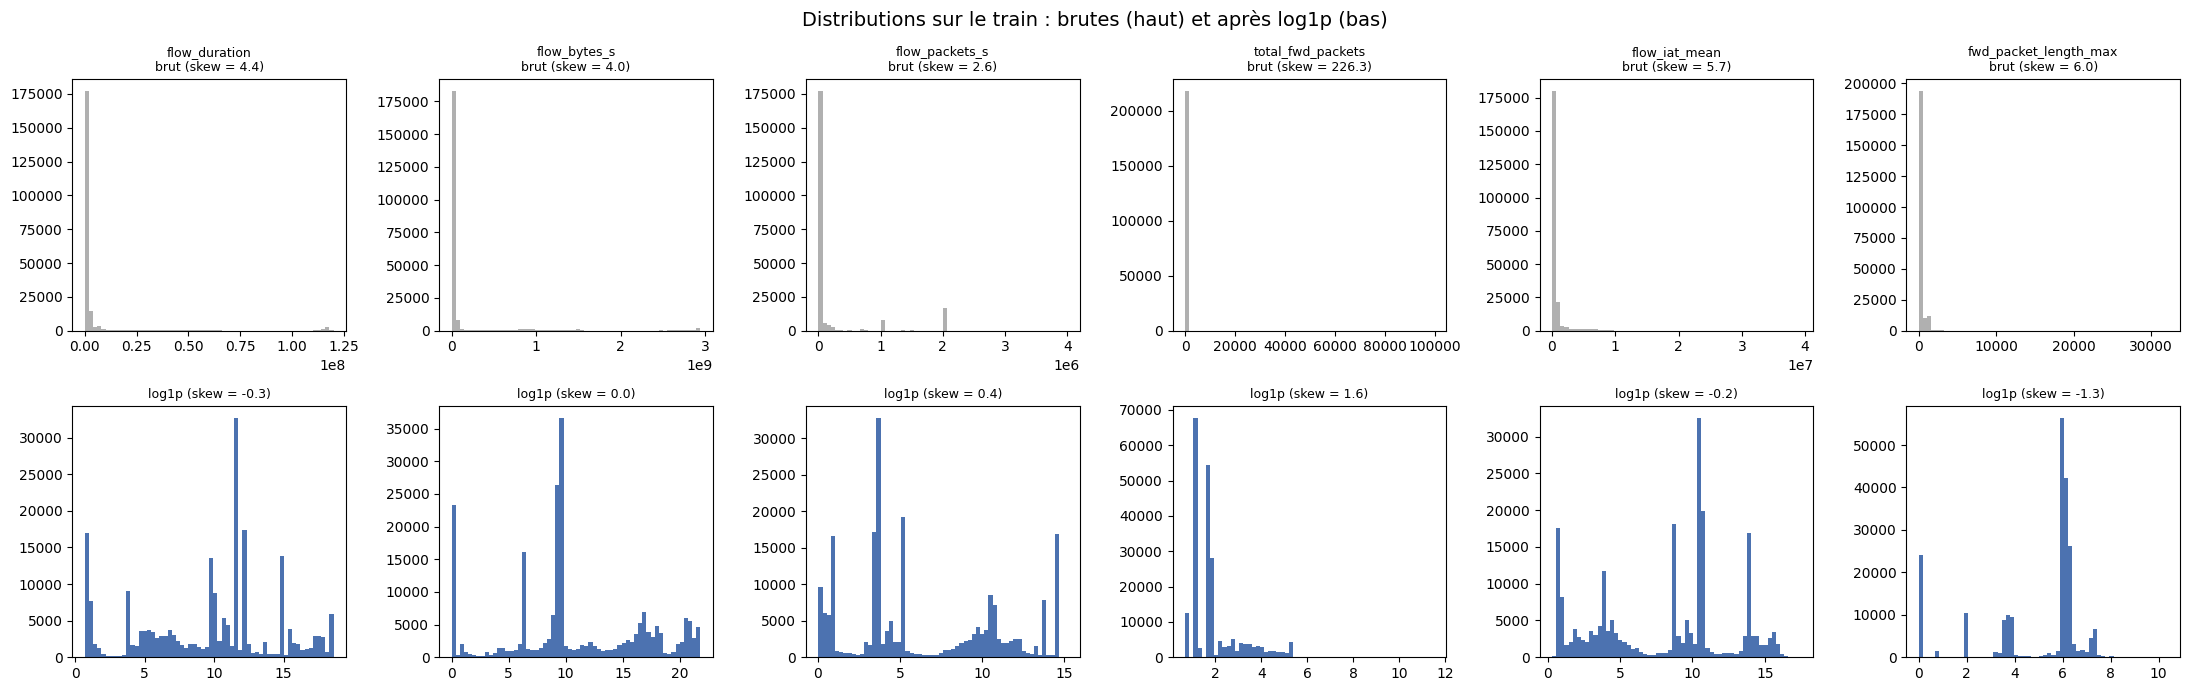


Effet des scalers sur flow_bytes_s (train) :
                        min   50%    99%    max
StandardScaler (brut) -0.31 -0.31   5.52   5.72
MinMaxScaler (brut)    0.00  0.00   0.97   1.00
RobustScaler (brut)   -0.00  0.00 246.50 254.81
log1p + RobustScaler  -0.99  0.00   1.28   1.29

Après transformation (train) : médianes ≈ 0 -> 0.0
Test transformé avec les paramètres du train (médiane du test, non nulle exactement) : 0.01
X_train : (217743, 46)   X_test : (93319, 46)


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# --- 0) Découpage 70/30 stratifié (détaillé en Q13) : le scaler ne verra que le train ---
CIBLES = ["label", "label_brut", "y_bin", "y_multi"]
X = df[FEATURES]
train_idx, test_idx = train_test_split(df.index, test_size=0.30, stratify=df["label"], random_state=42)
X_train, X_test = X.loc[train_idx].copy(), X.loc[test_idx].copy()
print(f"X_train : {X_train.shape}   X_test : {X_test.shape}")

# --- 1) Colonnes continues (les colonnes binaires 0/1 ne sont pas normalisées) ---
BINAIRES = [c for c in FEATURES if X_train[c].nunique() <= 2]
CONTINUES = [c for c in FEATURES if c not in BINAIRES]
print(f"{len(CONTINUES)} colonnes continues, {len(BINAIRES)} binaires laissées telles quelles : {BINAIRES}")

# --- 2) Asymétrie avant / après log1p signé (calculée sur le TRAIN) ---
def log1p_signe(a):
    return np.sign(a) * np.log1p(np.abs(a))

skew_brut = X_train[CONTINUES].skew()
skew_log = log1p_signe(X_train[CONTINUES].astype("float64")).skew()
tab_skew = pd.DataFrame({"skew brut": skew_brut, "skew après log1p": skew_log}).sort_values("skew brut", ascending=False)
pd.set_option("display.float_format", "{:,.2f}".format)
print("\nAsymétrie des 15 features les plus asymétriques :")
print(tab_skew.head(15).to_string())
for nom, s in [("brut", skew_brut), ("après log1p", skew_log)]:
    print(f"{nom:12s} : médiane |skew| = {s.abs().median():6.2f}  |  features avec |skew| > 1 : {(s.abs() > 1).sum()}/{len(s)}")

# --- 3) Histogrammes : brut vs log1p ---
EXEMPLES = ["flow_duration", "flow_bytes_s", "flow_packets_s", "total_fwd_packets", "flow_iat_mean", "fwd_packet_length_max"]
fig, axes = plt.subplots(2, len(EXEMPLES), figsize=(22, 7))
for j, c in enumerate(EXEMPLES):
    axes[0, j].hist(X_train[c], bins=60, color="#B0B0B0"); axes[0, j].set_title(f"{c}\nbrut (skew = {skew_brut[c]:.1f})", fontsize=9)
    axes[1, j].hist(log1p_signe(X_train[c].astype("float64")), bins=60, color="#4C72B0")
    axes[1, j].set_title(f"log1p (skew = {skew_log[c]:.1f})", fontsize=9)
fig.suptitle("Distributions sur le train : brutes (haut) et après log1p (bas)", fontsize=14)
plt.tight_layout(); plt.show()

# --- 4) Comparaison des scalers sur une feature très asymétrique (train) ---
c = "flow_bytes_s"
v = X_train[[c]].astype("float64")
comp = {
    "StandardScaler (brut)": StandardScaler().fit_transform(v).ravel(),
    "MinMaxScaler (brut)":   MinMaxScaler().fit_transform(v).ravel(),
    "RobustScaler (brut)":   RobustScaler().fit_transform(v).ravel(),
    "log1p + RobustScaler":  RobustScaler().fit_transform(log1p_signe(v)).ravel(),
}
print(f"\nEffet des scalers sur {c} (train) :")
print(pd.DataFrame({k: pd.Series(a).describe(percentiles=[.5, .99])[["min", "50%", "99%", "max"]] for k, a in comp.items()}).T.to_string())

# --- 5) Choix retenu : log1p signé + RobustScaler, ajusté sur le TRAIN uniquement ---
scaler = RobustScaler()
scaler.fit(log1p_signe(X_train[CONTINUES].astype("float64")))          # fit : TRAIN seulement
for part in (X_train, X_test):
    part[CONTINUES] = scaler.transform(log1p_signe(part[CONTINUES].astype("float64"))).astype("float32")

print("\nAprès transformation (train) : médianes ≈ 0 ->", round(float(X_train[CONTINUES].median().abs().max()), 3))
print("Test transformé avec les paramètres du train (médiane du test, non nulle exactement) :",
      round(float(X_test[CONTINUES].median().abs().max()), 3))
print(f"X_train : {X_train.shape}   X_test : {X_test.shape}")

**Résultat :**

- **Découpage :** `X_train` = 217 743 lignes, `X_test` = 93 319 lignes, avec 46 features.
- **38 colonnes continues** sont normalisées. Les **8 colonnes binaires** (`fwd_psh_flags`, `ack_flag_count`, `urg_flag_count`, `cwe_flag_count`, `inbound`, `protocol_0`, `protocol_6`, `protocol_17`) restent en 0/1.

**1. Asymétrie (sur le train) :** **toutes les 38 features continues** ont |skew| > 1, avec une **médiane |skew| de 7,75**. Les plus extrêmes dépassent 200 (ex. `total_fwd_packets` : 226). Les histogrammes bruts montrent une barre géante près de 0 et une longue traîne sur plusieurs ordres de grandeur, par exemple jusqu'à 10⁹ octets/s pour `flow_bytes_s`.

**2. Après `log1p` :** la médiane |skew| tombe à **1,91**, et les extrêmes passent de plus de 200 à moins de 6. Les histogrammes deviennent lisibles et font apparaître plusieurs **pics**, un par type d'attaque, au lieu d'une seule barre.

**3. Comparaison des scalers sur `flow_bytes_s` (train) :**

| Méthode | Min | Médiane | 99 % | Max | Problème |
|---|---:|---:|---:|---:|---|
| StandardScaler (brut) | −0,31 | −0,31 | 5,52 | 5,72 | Moyenne et écart-type tirés par les extrêmes : presque toutes les valeurs sont écrasées autour de −0,31 |
| MinMaxScaler (brut) | 0,00 | 0,00 | 0,97 | 1,00 | Le maximum fixe l'échelle : la majorité des flux est collée à 0 |
| RobustScaler (brut) | 0,00 | 0,00 | 246,5 | 254,8 | Médiane et IQR robustes, mais la traîne reste énorme (valeurs > 250) |
| **log1p + RobustScaler** | −0,99 | 0,00 | 1,28 | 1,29 | **Valeurs centrées sur 0, dans une plage d'environ ±1, sans écrasement** |

**Choix retenu : `log1p` signé suivi d'un `RobustScaler`.**

- **`log1p` d'abord :** les features de flux (durées, débits, octets, compteurs) sont positives et s'étalent sur plusieurs ordres de grandeur. Le logarithme réduit fortement l'asymétrie, et une variation ×10 devient un écart constant. La version signée `sign(x)·log(1+|x|)` accepte les quelques valeurs négatives, comme le −1 de `init_win_bytes_*`.
- **`RobustScaler` ensuite :** il centre sur la **médiane** et divise par l'**IQR**, deux statistiques insensibles aux valeurs extrêmes. Or on a choisi de **garder** ces valeurs, car ce sont les attaques (Q9). `StandardScaler` (moyenne et écart-type) et `MinMaxScaler` (min et max) seraient dominés par elles.
- **Pour les modèles :** cette mise à l'échelle profite aux modèles sensibles aux distances ou aux gradients (KNN, SVM, régression logistique). Pour les arbres, elle est neutre, et donc sans risque.

**Sans fuite de données :** le scaler a été ajusté (`fit`) **uniquement sur `X_train`**, puis appliqué (`transform`) au train et au test. La médiane du train transformé vaut exactement 0. Celle du test vaut 0,01, et non 0, ce qui confirme que le test a été transformé avec les paramètres du train, sans que ses propres statistiques soient utilisées.

### Question 13 — Découpage train/test (3 pts)

**Énoncé :** Produire un découpage 70/30 stratifié sur Label, avec random_state = 42. Afficher les tailles et la répartition des classes dans chaque ensemble. Discuter l'alternative « jour 1 en entraînement / jour 2 en test » : quelles classes posent problème et pourquoi ?

**Démarche :** le découpage a été créé en Q12, **avant** la normalisation, pour que le scaler ne voie jamais le test. On le reprend ici pour en vérifier les propriétés :

- `train_test_split(test_size=0.30, stratify=df["label"], random_state=42)` est **stratifié** sur les 14 classes harmonisées : chaque classe garde la même proportion dans le train et dans le test. C'est indispensable pour les classes rares (WebDDoS : 414 flux, Portmap : 771), qui pourraient sinon être quasi absentes du test.
- Les cibles `y_bin` et `y_multi` sont extraites avec les **mêmes indices** que `X_train` / `X_test`.
- Pour l'alternative « jour 1 / jour 2 », le jour de chaque flux est retrouvé grâce au nom brut du label (`label_brut`) : les fichiers `DrDoS_*`, TFTP, UDP-lag et WebDDoS viennent du 12 janvier, et LDAP, MSSQL, NetBIOS, Portmap, UDP et UDPLag du 11 mars.

Train : (217743, 46)  (70.0 %)
Test  : (93319, 46)  (30.0 %)

Répartition multiclasse :
         train (n)  test (n)  train (%)  test (%)  complet (%)  écart train/test (pts)
label                                                                                 
BENIGN       66720     28595      30.64     30.64        30.64                    0.00
UDP          35849     15364      16.46     16.46        16.46                    0.00
NTP          32957     14125      15.14     15.14        15.14                    0.00
SSDP         17972      7703       8.25      8.25         8.25                    0.00
TFTP         17590      7538       8.08      8.08         8.08                    0.00
MSSQL        17536      7515       8.05      8.05         8.05                    0.00
UDPLag        9519      4079       4.37      4.37         4.37                    0.00
Syn           5750      2465       2.64      2.64         2.64                    0.00
SNMP          4220      1809       1.94   

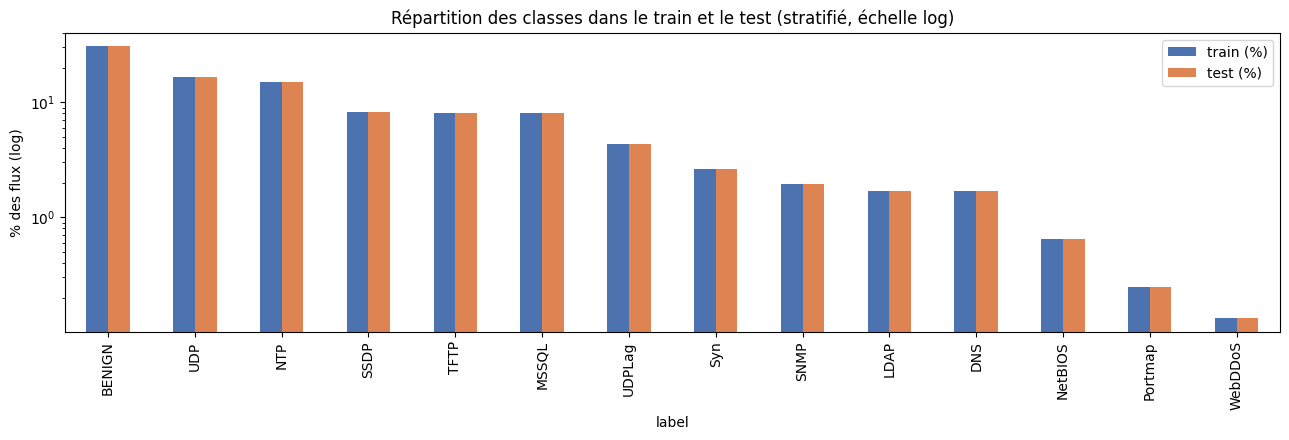


Présence de chaque classe selon le jour :
label
BENIGN      les deux jours
DNS                 jour 1
LDAP       jour 1 + jour 2
MSSQL      jour 1 + jour 2
NTP                 jour 1
NetBIOS    jour 1 + jour 2
Portmap             jour 2
SNMP                jour 1
SSDP                jour 1
Syn         les deux jours
TFTP                jour 1
UDP        jour 1 + jour 2
UDPLag     jour 1 + jour 2
WebDDoS             jour 1

Classes vues en entraînement mais ABSENTES du test (jour 2) : ['DNS', 'NTP', 'SNMP', 'SSDP', 'TFTP', 'WebDDoS']
Classes du test JAMAIS vues en entraînement (jour 1)      : ['Portmap']


In [30]:
# --- 1) Cibles alignées sur le découpage de la Q12 (mêmes indices) ---
y_train_bin,   y_test_bin   = df.loc[train_idx, "y_bin"],   df.loc[test_idx, "y_bin"]
y_train_multi, y_test_multi = df.loc[train_idx, "y_multi"], df.loc[test_idx, "y_multi"]
lab_train, lab_test = df.loc[train_idx, "label"], df.loc[test_idx, "label"]

n = len(df)
print(f"Train : {X_train.shape}  ({100*len(X_train)/n:.1f} %)")
print(f"Test  : {X_test.shape}  ({100*len(X_test)/n:.1f} %)")
assert set(train_idx).isdisjoint(test_idx), "Une ligne est à la fois dans le train et le test !"

# --- 2) Répartition des classes dans chaque ensemble ---
rep = pd.DataFrame({
    "train (n)": lab_train.value_counts(), "test (n)": lab_test.value_counts(),
    "train (%)": 100 * lab_train.value_counts(normalize=True),
    "test (%)": 100 * lab_test.value_counts(normalize=True),
    "complet (%)": 100 * df["label"].value_counts(normalize=True),
}).sort_values("train (n)", ascending=False)
rep["écart train/test (pts)"] = (rep["train (%)"] - rep["test (%)"]).abs()
pd.set_option("display.float_format", "{:,.2f}".format)
print("\nRépartition multiclasse :")
print(rep.to_string())
print(f"Écart maximal train/test : {rep['écart train/test (pts)'].max():.3f} point de %")

print("\nRépartition binaire (% d'attaques) : "
      f"train = {100*y_train_bin.mean():.2f} %, test = {100*y_test_bin.mean():.2f} %")

ax = rep[["train (%)", "test (%)"]].plot(kind="bar", figsize=(13, 4.5), logy=True, color=["#4C72B0", "#DD8452"])
ax.set_title("Répartition des classes dans le train et le test (stratifié, échelle log)")
ax.set_ylabel("% des flux (log)"); plt.tight_layout(); plt.show()

# --- 3) Alternative « jour 1 = train / jour 2 = test » ---
JOUR1 = {"DrDoS_DNS", "DrDoS_LDAP", "DrDoS_MSSQL", "DrDoS_NTP", "DrDoS_NetBIOS", "DrDoS_SNMP",
         "DrDoS_SSDP", "DrDoS_UDP", "TFTP", "UDP-lag", "WebDDoS"}          # fichiers 01-12
JOUR2 = {"LDAP", "MSSQL", "NetBIOS", "Portmap", "UDP", "UDPLag"}           # fichiers 03-11
# (Syn et BENIGN existent les deux jours)
def jour(l):
    return "jour 1" if l in JOUR1 else ("jour 2" if l in JOUR2 else "les deux jours")
presence = (df.assign(jour=df["label_brut"].map(jour))
              .groupby("label")["jour"].agg(lambda s: " + ".join(sorted(set(s)))))
cl_j1 = {c for c, j in presence.items() if "jour 1" in j or "deux" in j}
cl_j2 = {c for c, j in presence.items() if "jour 2" in j or "deux" in j}
print("\nPrésence de chaque classe selon le jour :")
print(presence.to_string())
print("\nClasses vues en entraînement mais ABSENTES du test (jour 2) :", sorted(cl_j1 - cl_j2))
print("Classes du test JAMAIS vues en entraînement (jour 1)      :", sorted(cl_j2 - cl_j1))

**Résultat du découpage stratifié :**

- **Train : 217 743 lignes (70,0 %)**, **test : 93 319 lignes (30,0 %)**, avec 46 features. Aucune ligne n'est commune aux deux ensembles (vérifié par `assert`).
- **Cible binaire :** 69,36 % d'attaques dans le train **comme** dans le test.

| Classe | Train (n) | Test (n) | Train (%) | Test (%) |
|---|---:|---:|---:|---:|
| BENIGN | 66 720 | 28 595 | 30,64 | 30,64 |
| UDP | 35 849 | 15 364 | 16,46 | 16,46 |
| NTP | 32 957 | 14 125 | 15,14 | 15,14 |
| SSDP | 17 972 | 7 703 | 8,25 | 8,25 |
| TFTP | 17 590 | 7 538 | 8,08 | 8,08 |
| MSSQL | 17 536 | 7 515 | 8,05 | 8,05 |
| UDPLag | 9 519 | 4 079 | 4,37 | 4,37 |
| Syn | 5 750 | 2 465 | 2,64 | 2,64 |
| SNMP | 4 220 | 1 809 | 1,94 | 1,94 |
| LDAP | 3 717 | 1 593 | 1,71 | 1,71 |
| DNS | 3 668 | 1 572 | 1,68 | 1,68 |
| NetBIOS | 1 415 | 606 | 0,65 | 0,65 |
| Portmap | 540 | 231 | 0,25 | 0,25 |
| WebDDoS | 290 | 124 | 0,13 | 0,13 |

L'**écart maximal** entre les proportions du train et du test est de **0,001 point de %** : la stratification reproduit exactement la distribution du jeu complet. Même WebDDoS, la classe la plus rare, a 124 exemples dans le test, assez pour mesurer un rappel.

**Alternative « jour 1 (12 janvier) en entraînement / jour 2 (11 mars) en test » :**

| Situation | Classes | Problème |
|---|---|---|
| Présentes seulement le **jour 1** → **absentes du test** | DNS, NTP, SNMP, SSDP, TFTP, WebDDoS | Le modèle les apprend mais on ne peut **jamais mesurer** sa performance sur elles : 6 classes sur 14 sans évaluation |
| Présente seulement le **jour 2** → **jamais vue à l'entraînement** | **Portmap** | Le modèle ne peut pas prédire une classe qu'il ne connaît pas : ses flux seront forcément mal classés, sans doute en NetBIOS ou LDAP, qui lui ressemblent (Q7). Rappel multiclasse de Portmap = 0 |
| Présentes les **deux jours** | BENIGN, Syn, LDAP, MSSQL, NetBIOS, UDP, UDPLag | Évaluables, mais avec un **décalage de distribution** : outils, machines (IP différentes, cf. Q1), volumes et proportions changent entre les deux jours |

**Pourquoi ce découpage reste intéressant :** c'est le scénario le plus **réaliste** pour un IDS. On entraîne sur le passé et on teste sur une période future, avec des attaques nouvelles (comme Portmap, prévue par les auteurs comme attaque « inconnue ») et une dérive du trafic. Il mesure la **généralisation**, alors que le découpage aléatoire mesure surtout l'interpolation : des flux du même jour, souvent très semblables, se retrouvent des deux côtés.

**Choix retenu :** le découpage **aléatoire stratifié 70/30** demandé, parce qu'il garantit que les 14 classes sont présentes et évaluables dans les deux ensembles. Il faut garder en tête que ses scores seront **optimistes** par rapport à un déploiement réel. En binaire, le scénario jour 1 / jour 2 resterait utilisable (BENIGN et des attaques existent les deux jours), et il serait un bon test complémentaire de robustesse.

## Partie E — Déséquilibre et familles d'attaques (6 pts)
### Question 14 — Déséquilibre des classes (3 pts)

**Énoncé :** Calculer le ratio entre la classe majoritaire et la classe minoritaire. Appliquer une stratégie (sous-échantillonnage aléatoire, SMOTE ou class_weight) sur le train seulement, et montrer la distribution avant/après par un graphique. Expliquer pourquoi le test ne doit jamais être rééquilibré.

**Stratégie retenue : hybride, sous-échantillonnage aléatoire + SMOTE**, appliquée **uniquement sur `X_train`** (cible multiclasse `y_multi`) :

1. **Sous-échantillonnage aléatoire** (`RandomUnderSampler`) des classes de plus de **20 000** flux (BENIGN, UDP, NTP), ramenées à 20 000. On retire des flux très nombreux et souvent redondants sans perdre de diversité utile.
2. **SMOTE** sur les classes de moins de **5 000** flux (SNMP, LDAP, DNS, NetBIOS, Portmap, WebDDoS), portées à 5 000. SMOTE crée des flux **synthétiques** par interpolation entre un flux et ses k = 5 plus proches voisins de la même classe, au lieu de simplement dupliquer des lignes.
3. Les **colonnes binaires** (drapeaux, `protocol_*`, `inbound`) sont **arrondies à 0/1** après SMOTE, car une interpolation donnerait des valeurs comme 0,4 sans signification.

Les classes intermédiaires (SSDP, TFTP, MSSQL, UDPLag, Syn) restent inchangées. On compare aussi avec `class_weight="balanced"`, qui ne modifie pas les données mais pondère la fonction de perte.

imbalanced-learn 0.14.2
Classe majoritaire : BENIGN (66,720)  |  minoritaire : WebDDoS (290)
Ratio majoritaire / minoritaire = 230.1

Train : (217743, 46) -> (158367, 46)
         avant  après               méthode
y_multi                                    
BENIGN   66720  20000  sous-échantillonnage
UDP      35849  20000  sous-échantillonnage
NTP      32957  20000  sous-échantillonnage
SSDP     17972  17972             inchangée
TFTP     17590  17590             inchangée
MSSQL    17536  17536             inchangée
UDPLag    9519   9519             inchangée
Syn       5750   5750             inchangée
SNMP      4220   5000                 SMOTE
LDAP      3717   5000                 SMOTE
DNS       3668   5000                 SMOTE
NetBIOS   1415   5000                 SMOTE
Portmap    540   5000                 SMOTE
WebDDoS    290   5000                 SMOTE
Nouveau ratio majoritaire / minoritaire = 4.0
Test inchangé : (93319, 46)


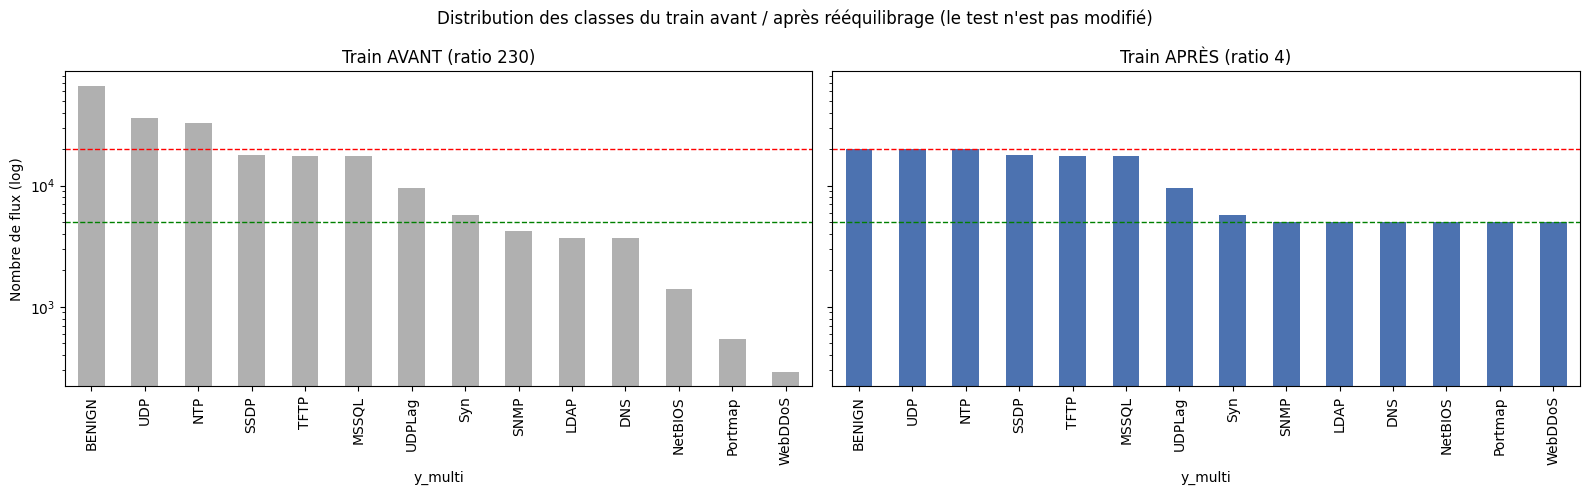


Poids class_weight='balanced' (alternative) :
BENIGN     0.23
UDP        0.43
NTP        0.47
SSDP       0.87
TFTP       0.88
MSSQL      0.89
UDPLag     1.63
Syn        2.70
SNMP       3.69
LDAP       4.18
DNS        4.24
NetBIOS   10.99
Portmap   28.80
WebDDoS   53.63


In [31]:
try:
    import imblearn
except ImportError:
    !pip install -q imbalanced-learn
    import imblearn
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_class_weight
print("imbalanced-learn", imblearn.__version__)

noms = dict(enumerate(le.classes_))                       # code -> nom de classe (Q11)
avant = y_train_multi.map(noms).value_counts()

# --- 1) Ratio majoritaire / minoritaire (sur le TRAIN) ---
ratio = avant.max() / avant.min()
print(f"Classe majoritaire : {avant.idxmax()} ({avant.max():,})  |  minoritaire : {avant.idxmin()} ({avant.min():,})")
print(f"Ratio majoritaire / minoritaire = {ratio:.1f}")

# --- 2) Rééquilibrage du TRAIN uniquement : sous-échantillonnage puis SMOTE ---
PLAFOND, PLANCHER = 20_000, 5_000
cnt = y_train_multi.value_counts()
strat_under = {c: PLAFOND for c, n in cnt.items() if n > PLAFOND}
rus = RandomUnderSampler(sampling_strategy=strat_under, random_state=42)
X_tmp, y_tmp = rus.fit_resample(X_train, y_train_multi)

cnt_tmp = pd.Series(y_tmp).value_counts()
strat_over = {c: PLANCHER for c, n in cnt_tmp.items() if n < PLANCHER}
smote = SMOTE(sampling_strategy=strat_over, k_neighbors=5, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_tmp, y_tmp)
X_train_res[BINAIRES] = X_train_res[BINAIRES].round().clip(0, 1)   # colonnes 0/1 restent 0/1

apres = pd.Series(y_train_res).map(noms).value_counts()
tab = pd.DataFrame({"avant": avant, "après": apres}).fillna(0).astype(int).sort_values("avant", ascending=False)
tab["méthode"] = np.where(tab["avant"] > PLAFOND, "sous-échantillonnage",
                  np.where(tab["avant"] < PLANCHER, "SMOTE", "inchangée"))
print(f"\nTrain : {X_train.shape} -> {X_train_res.shape}")
print(tab.to_string())
print(f"Nouveau ratio majoritaire / minoritaire = {apres.max() / apres.min():.1f}")
print(f"Test inchangé : {X_test.shape}")

# --- 3) Graphique avant / après ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, col, titre, coul in [(axes[0], "avant", f"Train AVANT (ratio {ratio:.0f})", "#B0B0B0"),
                             (axes[1], "après", f"Train APRÈS (ratio {apres.max()/apres.min():.0f})", "#4C72B0")]:
    tab[col].plot(kind="bar", ax=ax, color=coul, logy=True)
    ax.set_title(titre); ax.set_ylabel("Nombre de flux (log)")
    ax.axhline(PLAFOND, ls="--", c="red", lw=1); ax.axhline(PLANCHER, ls="--", c="green", lw=1)
fig.suptitle("Distribution des classes du train avant / après rééquilibrage (le test n'est pas modifié)")
plt.tight_layout(); plt.show()

# --- 4) Alternative sans modifier les données : class_weight ---
cw = compute_class_weight("balanced", classes=np.unique(y_train_multi), y=y_train_multi)
poids = pd.Series(cw, index=[noms[c] for c in np.unique(y_train_multi)]).sort_values()
print("\nPoids class_weight='balanced' (alternative) :")
print(poids.round(2).to_string())

**Résultat :**

**Ratio avant rééquilibrage (train) :** BENIGN, la classe majoritaire, compte 66 720 flux, contre 290 pour WebDDoS, la minoritaire, soit un **ratio de 230,1**. Sans traitement, un modèle verrait 230 fois plus d'exemples BENIGN que WebDDoS : il aurait intérêt à ignorer les classes rares pour maximiser son exactitude globale.

| Classe | Avant | Après | Méthode |
|---|---:|---:|---|
| BENIGN | 66 720 | 20 000 | sous-échantillonnage |
| UDP | 35 849 | 20 000 | sous-échantillonnage |
| NTP | 32 957 | 20 000 | sous-échantillonnage |
| SSDP | 17 972 | 17 972 | inchangée |
| TFTP | 17 590 | 17 590 | inchangée |
| MSSQL | 17 536 | 17 536 | inchangée |
| UDPLag | 9 519 | 9 519 | inchangée |
| Syn | 5 750 | 5 750 | inchangée |
| SNMP | 4 220 | 5 000 | SMOTE |
| LDAP | 3 717 | 5 000 | SMOTE |
| DNS | 3 668 | 5 000 | SMOTE |
| NetBIOS | 1 415 | 5 000 | SMOTE |
| Portmap | 540 | 5 000 | SMOTE |
| WebDDoS | 290 | 5 000 | SMOTE |

**Après :** le train passe de **217 743 à 158 367 lignes** et le ratio tombe de **230 à 4,0**. Le test reste **inchangé (93 319 lignes)**.

**Pourquoi cette stratégie hybride :**

- **Sous-échantillonnage seul jusqu'à la classe minoritaire (290)** : on garderait seulement 14 × 290 ≈ 4 000 lignes et on jetterait plus de 98 % du train, ce qui ferait perdre beaucoup d'information.
- **SMOTE seul jusqu'à la classe majoritaire (66 720)** : on créerait plus de 700 000 flux synthétiques. WebDDoS passerait de 290 réels à 66 720 dont 99,6 % artificiels, avec un fort risque de sur-apprentissage sur des points inventés.
- **Le compromis** (plafond 20 000, plancher 5 000) limite les deux défauts : on retire seulement des flux redondants des grosses classes, et on multiplie au plus par 17 la plus petite classe.
- **Alternative `class_weight="balanced"`** : elle ne modifie pas les données et donne à chaque classe un poids inversement proportionnel à son effectif, d'environ 0,23 pour BENIGN à 53,6 pour WebDDoS. Elle est simple et sans données synthétiques, mais tous les modèles ne l'acceptent pas (KNN, par exemple). Elle reste une bonne option pour les forêts aléatoires et la régression logistique.

**Pourquoi le test ne doit JAMAIS être rééquilibré :**

1. **Le test doit représenter la réalité.** En production, l'IDS verra la vraie distribution du trafic, avec ses classes rares. Si on rééquilibrait le test, les scores (précision, F1, taux de fausses alarmes) correspondraient à un monde artificiel.
2. **SMOTE sur le test = données inventées.** On évaluerait le modèle sur des flux qui n'ont jamais existé, souvent très proches des points synthétiques du train, ce qui donne des scores **gonflés**.
3. **Sous-échantillonner le test** reviendrait à jeter des exemples réels et changerait la précision des classes rares, qui dépend directement de leur proportion.
4. **Fuite de données :** SMOTE utilise les plus proches voisins. Appliqué avant le découpage, ou sur le test, il ferait passer de l'information du test vers le train.

C'est pourquoi le rééquilibrage est fait **après** le découpage (Q13) et **après** la normalisation (Q12), sur `X_train` seulement. Dans le pipeline final (Q16), il faudrait utiliser un `imblearn.pipeline.Pipeline`, qui n'applique l'échantillonnage que lors du `fit`.

### Question 15 — Regroupement par familles (3 pts)

**Énoncé :** Créer une colonne `attack_family` (Benign, Reflection, Exploitation) à partir des labels bruts. Classer WebDDoS en justifiant votre choix. Rejouer les étapes 11 à 13 pour la cible `attack_family` et comparer les répartitions obtenues.

**Correspondance labels bruts → famille** (taxonomie de Sharafaldin et al., 2019, cf. Q2) :

| Famille | Labels bruts |
|---|---|
| **Benign** | BENIGN |
| **Reflection** | DrDoS_DNS, DrDoS_LDAP, LDAP, DrDoS_MSSQL, MSSQL, DrDoS_NTP, DrDoS_NetBIOS, NetBIOS, DrDoS_SNMP, DrDoS_SSDP, TFTP, Portmap |
| **Exploitation** | Syn, DrDoS_UDP, UDP, UDP-lag, UDPLag, **WebDDoS** |

**Classement de WebDDoS → Exploitation.** WebDDoS est une inondation **HTTP** envoyée **directement** au serveur web victime (192.168.50.1 / .4). Il n'y a **pas de serveur tiers** (réflecteur) qui renvoie le trafic, et donc **pas d'usurpation d'adresse ni d'amplification**, qui sont les deux caractéristiques de la réflexion. L'attaque épuise les ressources du serveur en abusant d'un protocole légitime (connexions TCP + requêtes HTTP), comme Syn abuse de la poignée de main TCP. C'est la définition d'une attaque par **exploitation**. Le préfixe *DrDoS* (« Distributed **Reflection** DoS ») est d'ailleurs absent de son nom.

**Étapes rejouées pour la cible `attack_family` :** Q11 (encodage de la nouvelle cible avec `LabelEncoder`), Q13 (nouveau découpage 70/30 **stratifié sur `attack_family`**, `random_state = 42`) et Q12 (`log1p` + `RobustScaler` réajusté sur ce **nouveau train** seulement). Le découpage passe avant la normalisation, comme en Q12, pour éviter toute fuite.

attack_family
Benign                                                     BENIGN
Exploitation        DrDoS_UDP, Syn, UDP, UDP-lag, UDPLag, WebDDoS
Reflection      DrDoS_DNS, DrDoS_LDAP, DrDoS_MSSQL, DrDoS_NTP,...

Codes : {'Benign': 0, 'Exploitation': 1, 'Reflection': 2}

Xf_train : (217743, 46)   Xf_test : (93319, 46)

Répartition par famille :
               complet (n)  train (n)  test (n)  train (%)  test (%)
attack_family                                                       
Reflection          142307      99615     42692      45.75     45.75
Benign               95315      66720     28595      30.64     30.64
Exploitation         73440      51408     22032      23.61     23.61

Comparaison des cibles :
                              nb classes  plus grande classe (train)  plus petite classe (train)  ratio max/min (train)
labels bruts                          19                       66720                         290                 230.07
multiclasse harmonisée (Q11)          14  

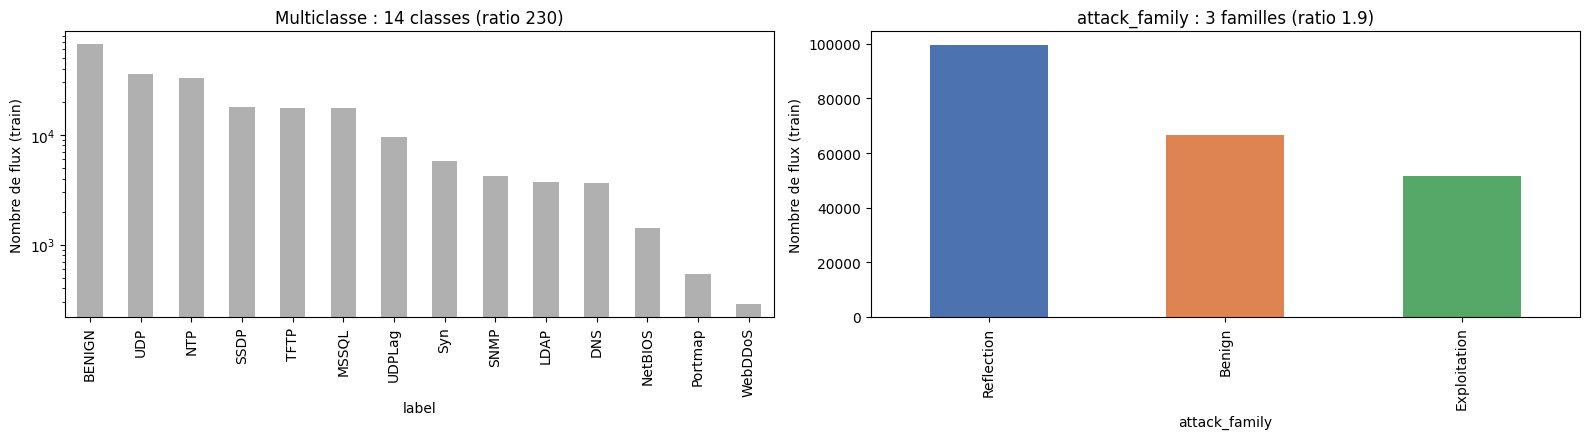

In [32]:
# --- 1) Colonne attack_family à partir des labels BRUTS ---
REFLECTION = {"DrDoS_DNS", "DrDoS_LDAP", "LDAP", "DrDoS_MSSQL", "MSSQL", "DrDoS_NTP",
              "DrDoS_NetBIOS", "NetBIOS", "DrDoS_SNMP", "DrDoS_SSDP", "TFTP", "Portmap"}
EXPLOITATION = {"Syn", "DrDoS_UDP", "UDP", "UDP-lag", "UDPLag", "WebDDoS"}   # WebDDoS : exploitation (HTTP direct)

def famille(l):
    if l == "BENIGN":     return "Benign"
    if l in REFLECTION:   return "Reflection"
    if l in EXPLOITATION: return "Exploitation"
    raise ValueError(f"Label non classé : {l}")

df["attack_family"] = df["label_brut"].map(famille)
print(df.groupby("attack_family")["label_brut"].unique().apply(lambda v: ", ".join(sorted(v))).to_string())

# --- 2) Étape 11 rejouée : encodage de la nouvelle cible ---
le_fam = LabelEncoder()
df["y_family"] = le_fam.fit_transform(df["attack_family"]).astype("int8")
print("\nCodes :", dict(zip(le_fam.classes_, range(len(le_fam.classes_)))))

# --- 3) Étape 13 rejouée : découpage 70/30 stratifié sur attack_family ---
tr_f, te_f = train_test_split(df.index, test_size=0.30, stratify=df["attack_family"], random_state=42)
Xf_train, Xf_test = df.loc[tr_f, FEATURES].copy(), df.loc[te_f, FEATURES].copy()
yf_train, yf_test = df.loc[tr_f, "y_family"], df.loc[te_f, "y_family"]
print(f"\nXf_train : {Xf_train.shape}   Xf_test : {Xf_test.shape}")

# --- 4) Étape 12 rejouée : log1p + RobustScaler ajusté sur CE train ---
scaler_f = RobustScaler().fit(log1p_signe(Xf_train[CONTINUES].astype("float64")))
for part in (Xf_train, Xf_test):
    part[CONTINUES] = scaler_f.transform(log1p_signe(part[CONTINUES].astype("float64"))).astype("float32")

# --- 5) Comparaison des répartitions ---
fam_train, fam_test = df.loc[tr_f, "attack_family"], df.loc[te_f, "attack_family"]
rep_f = pd.DataFrame({
    "complet (n)": df["attack_family"].value_counts(),
    "train (n)": fam_train.value_counts(), "test (n)": fam_test.value_counts(),
    "train (%)": 100 * fam_train.value_counts(normalize=True),
    "test (%)": 100 * fam_test.value_counts(normalize=True),
})
print("\nRépartition par famille :")
print(rep_f.to_string())

def ratio(s): return s.max() / s.min()
comp = pd.DataFrame({
    "nb classes": [df["label_brut"].nunique(), df["label"].nunique(), df["attack_family"].nunique()],
    "plus grande classe (train)": [df.loc[train_idx, "label_brut"].value_counts().max(), lab_train.value_counts().max(), fam_train.value_counts().max()],
    "plus petite classe (train)": [df.loc[train_idx, "label_brut"].value_counts().min(), lab_train.value_counts().min(), fam_train.value_counts().min()],
    "ratio max/min (train)": [ratio(df.loc[train_idx, "label_brut"].value_counts()), ratio(lab_train.value_counts()), ratio(fam_train.value_counts())],
}, index=["labels bruts", "multiclasse harmonisée (Q11)", "attack_family"])
print("\nComparaison des cibles :")
print(comp.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
lab_train.value_counts().plot(kind="bar", ax=axes[0], logy=True, color="#B0B0B0",
                               title=f"Multiclasse : 14 classes (ratio {ratio(lab_train.value_counts()):.0f})")
fam_train.value_counts().plot(kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452", "#55A868"],
                               title=f"attack_family : 3 familles (ratio {ratio(fam_train.value_counts()):.1f})")
for ax in axes: ax.set_ylabel("Nombre de flux (train)")
plt.tight_layout(); plt.show()

**Résultat :**

- **Encodage (Q11 rejouée) :** Benign = 0, Exploitation = 1, Reflection = 2.
- **Découpage (Q13 rejoué) :** `Xf_train` = 217 743 lignes, `Xf_test` = 93 319 lignes, avec 46 features. Le découpage est stratifié sur `attack_family`, avec `random_state = 42`.
- **Normalisation (Q12 rejouée) :** `log1p` + `RobustScaler`, ajusté sur `Xf_train` uniquement.

| Famille | Jeu complet | Train (n) | Test (n) | Train (%) | Test (%) |
|---|---:|---:|---:|---:|---:|
| Reflection | 142 307 | 99 615 | 42 692 | 45,75 | 45,75 |
| Benign | 95 315 | 66 720 | 28 595 | 30,64 | 30,64 |
| Exploitation | 73 440 | 51 408 | 22 032 | 23,61 | 23,61 |

**Comparaison des cibles (sur le train) :**

| Cible | Nb classes | Plus grande | Plus petite | Ratio max / min |
|---|---:|---:|---:|---:|
| Labels bruts | 19 | 66 720 (BENIGN) | 290 (WebDDoS) | 230,1 |
| Multiclasse harmonisée (Q11) | 14 | 66 720 (BENIGN) | 290 (WebDDoS) | 230,1 |
| **`attack_family`** | **3** | 99 615 (Reflection) | 51 408 (Exploitation) | **1,9** |

**Commentaire :**

1. **Le déséquilibre disparait presque.** On passe d'un ratio de 230 à **1,9**. Les classes rares (WebDDoS : 290, Portmap : 540, NetBIOS : 1 415) sont absorbées dans des familles de plus de 50 000 flux. Pour cette cible, **aucun rééquilibrage (Q14) n'est nécessaire**. Au plus, un `class_weight` léger suffirait.
2. **La classe majoritaire change** : c'est **Reflection** (45,75 %), qui regroupe 12 labels bruts, et non plus BENIGN (30,64 %). Benign garde exactement la même proportion, puisque sa définition ne change pas.
3. **La stratification reste parfaite** : les proportions sont identiques dans le train et le test pour les 3 familles.
4. **Le problème de l'ambiguïté se règle de lui-même :** les flux identiques portant des labels différents (Q7 : NetBIOS / DrDoS_NetBIOS / Portmap, LDAP / DrDoS_LDAP) tombent presque tous dans la **même famille** (Reflection). La cible `attack_family` est donc beaucoup plus facile à apprendre et plus robuste.
5. **Intérêt pratique :** pour un IDS, savoir qu'une attaque est par **réflexion** (filtrer les réponses des services UDP réfléchis) ou par **exploitation** (protéger la pile TCP ou le serveur web) suffit souvent à déclencher la bonne contre-mesure. C'est une granularité intermédiaire entre le binaire (Q11) et les 14 classes, au prix d'une information moins fine.
6. **Alternative jour 1 / jour 2 (Q13) :** avec `attack_family`, les 3 familles existent **les deux jours**. Portmap, jamais vue à l'entraînement, appartient à une famille connue (Reflection). Ce découpage deviendrait donc **évaluable**, ce qui n'était pas le cas en multiclasse.

## Partie F — Pipeline et export (3 pts)
### Question 16 — Pipeline reproductible (3 pts)

**Énoncé :** Regrouper encodage, normalisation et éventuellement sélection dans un Pipeline / ColumnTransformer scikit-learn. Sauvegarder le pipeline ajusté avec joblib et exporter les jeux train/test au format Parquet. Vérifier en rechargeant les fichiers que les dimensions sont identiques.

**Architecture du pipeline :** il prend en entrée les **colonnes brutes retenues**, avec `protocol` sous sa forme d'origine (0 / 6 / 17), et réalise en une seule étape tout ce qui a été fait à la main en Q10 à Q12 :

| Bloc du `ColumnTransformer` | Colonnes | Transformation | Question |
|---|---|---|---|
| `continues` | 38 features continues | `FunctionTransformer(log1p signé)` → `RobustScaler` | Q12 |
| `protocole` | `protocol` | `OneHotEncoder(handle_unknown="ignore")` | Q11 |
| `binaires` | 5 drapeaux / `inbound` | `passthrough` (déjà 0/1) | — |

- **Sélection :** la liste des colonnes d'entrée est celle obtenue après les Q4, Q5, Q8 et Q10. Les colonnes absentes de cette liste sont ignorées (`remainder="drop"`).
- **Reproductibilité et absence de fuite :** `pipeline.fit(X_train)` apprend les médianes, les IQR et les catégories **sur le train uniquement**. `pipeline.transform(X_test)` applique ensuite ces mêmes paramètres au test, comme à toute nouvelle donnée en production.
- **Rééquilibrage :** il n'est **pas** inclus dans ce pipeline de prétraitement, car il ne doit jamais toucher au test (Q14). Pour l'entraînement d'un modèle, on l'ajouterait avec un `imblearn.pipeline.Pipeline`, qui n'applique SMOTE et le sous-échantillonnage que pendant le `fit`.

In [33]:
import joblib, sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

# --- 0) Données d'entrée « brutes » : protocol reconstruit sous sa forme d'origine (0/6/17) ---
PROTO_COLS = [c for c in FEATURES if c.startswith("protocol_")]
BIN_COLS = [c for c in BINAIRES if c not in PROTO_COLS]
X_brut = df[CONTINUES + BIN_COLS].copy()
X_brut["protocol"] = (df[PROTO_COLS].idxmax(axis=1).str.replace("protocol_", "").astype(int))
X_brut_train, X_brut_test = X_brut.loc[train_idx], X_brut.loc[test_idx]     # même découpage qu'en Q12/Q13

# --- 1) Pipeline : encodage + normalisation (+ sélection par la liste des colonnes) ---
def log1p_signe(a):
    return np.sign(a) * np.log1p(np.abs(a))

pretraitement = ColumnTransformer([
    ("continues", Pipeline([
        ("log1p", FunctionTransformer(log1p_signe, feature_names_out="one-to-one")),
        ("scaler", RobustScaler()),
    ]), CONTINUES),
    ("protocole", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype="int8"), ["protocol"]),
    ("binaires", "passthrough", BIN_COLS),
], remainder="drop", verbose_feature_names_out=False)
pipeline = Pipeline([("pretraitement", pretraitement)])

pipeline.fit(X_brut_train)                                   # fit : TRAIN seulement
noms_sortie = pipeline.get_feature_names_out()
Xp_train = pd.DataFrame(pipeline.transform(X_brut_train), columns=noms_sortie, index=train_idx).astype("float32")
Xp_test  = pd.DataFrame(pipeline.transform(X_brut_test),  columns=noms_sortie, index=test_idx).astype("float32")
print(pipeline)
print(f"\nSortie du pipeline : train {Xp_train.shape}, test {Xp_test.shape}")

# Contrôle : le pipeline reproduit exactement le prétraitement manuel des Q11-Q12
ecart = (Xp_train[X_train.columns].astype("float64") - X_train.astype("float64")).abs().to_numpy().max()
print(f"Écart max avec X_train manuel (Q12) : {ecart:.2e}")

# --- 2) Sauvegarde du pipeline ajusté (joblib) ---
EXPORT = "/content/drive/MyDrive/CICDDoS2019_cache/export"
os.makedirs(EXPORT, exist_ok=True)
joblib.dump(pipeline, f"{EXPORT}/pipeline_pretraitement.joblib")

# --- 3) Export Parquet : features transformées + cibles ---
CIBLES_EXPORT = ["label", "label_brut", "attack_family", "y_bin", "y_multi"]
train_export = pd.concat([Xp_train, df.loc[train_idx, CIBLES_EXPORT]], axis=1).reset_index(drop=True)
test_export  = pd.concat([Xp_test,  df.loc[test_idx,  CIBLES_EXPORT]], axis=1).reset_index(drop=True)
train_export.to_parquet(f"{EXPORT}/train.parquet", index=False)
test_export.to_parquet(f"{EXPORT}/test.parquet", index=False)
for f in sorted(os.listdir(EXPORT)):
    print(f"{f:32s} {os.path.getsize(f'{EXPORT}/{f}')/1e6:8.2f} Mo")

# --- 4) Vérification : rechargement et comparaison des dimensions ---
train_rel = pd.read_parquet(f"{EXPORT}/train.parquet")
test_rel  = pd.read_parquet(f"{EXPORT}/test.parquet")
pipe_rel  = joblib.load(f"{EXPORT}/pipeline_pretraitement.joblib")

verif = pd.DataFrame({
    "en mémoire": [train_export.shape, test_export.shape],
    "rechargé":   [train_rel.shape, test_rel.shape],
}, index=["train", "test"])
verif["identique"] = verif["en mémoire"] == verif["rechargé"]
print("\n", verif.to_string())
assert train_rel.equals(train_export) and test_rel.equals(test_export)
assert np.allclose(pipe_rel.transform(X_brut_test), Xp_test.to_numpy(), atol=1e-5)
print("\nContenu identique après rechargement, et le pipeline rechargé reproduit la même transformation du test.")
print(f"Versions : scikit-learn {sklearn.__version__}, pandas {pd.__version__}, numpy {np.__version__}, joblib {joblib.__version__}")

Pipeline(steps=[('pretraitement',
                 ColumnTransformer(transformers=[('continues',
                                                  Pipeline(steps=[('log1p',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function log1p_signe at 0x7e3039292200>)),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['flow_duration',
                                                   'total_fwd_packets',
                                                   'total_backward_packets',
                                                   'total_length_of_fwd_packets',
                                                   'fwd_packet_length_max',
                                  

**Résultat :**

- **Pipeline ajusté sur le train :** il produit **46 colonnes** en sortie, pour 217 743 lignes dans le train et 93 319 dans le test.
- **Contrôle de cohérence :** l'écart maximal avec le prétraitement manuel des Q11 et Q12 est de **3,8 × 10⁻⁶**, soit l'arrondi du float32. Le pipeline reproduit donc exactement les étapes faites à la main, en un seul objet réutilisable.

**Fichiers exportés** dans `MyDrive/CICDDoS2019_cache/export/` :

| Fichier | Taille | Contenu |
|---|---:|---|
| `pipeline_pretraitement.joblib` | 0,01 Mo | Pipeline ajusté (médianes, IQR, catégories de `protocol`) |
| `train.parquet` | 11,88 Mo | 46 features transformées + `label`, `label_brut`, `attack_family`, `y_bin`, `y_multi` |
| `test.parquet` | 5,25 Mo | Idem, transformé avec les paramètres du train |

**Vérification après rechargement :**

| | En mémoire | Rechargé | Identique |
|---|---|---|---|
| Train | 217 743 × 51 | 217 743 × 51 | ✅ |
| Test | 93 319 × 51 | 93 319 × 51 | ✅ |

Le **contenu** est lui aussi identique (`DataFrame.equals`), et le pipeline rechargé avec `joblib.load` transforme le test exactement comme l'original (`np.allclose`).

**Pourquoi Parquet et joblib :** Parquet est un format **colonnaire et compressé**. Il conserve les types (float32, int8, texte), et les 311 062 lignes tiennent dans 17 Mo, contre plusieurs centaines de Mo en CSV. Joblib sérialise efficacement les objets scikit-learn contenant des tableaux NumPy. Pour recharger le pipeline dans une nouvelle session, il faut que la fonction `log1p_signe` soit définie avant `joblib.load` (sérialisation par référence), et utiliser **la même version de scikit-learn (1.6.1)**.

**Versions utilisées :** scikit-learn 1.6.1, pandas 2.2.3, NumPy 2.1.3, joblib 1.6.0.

---

### Tableau récapitulatif : taille du jeu après chaque étape

| Étape | Opération | Lignes | Colonnes |
|---|---|---:|---:|
| Données brutes | 18 CSV CIC-DDoS2019 (Kaggle) | 70 427 637 | 88 |
| Q3 | Échantillonnage stratifié plafonné (≈ 50 000 / classe, BENIGN complet) | 916 769 | 88 |
| Q4 | Doublons de colonnes supprimés, snake_case | 916 769 | 82 |
| Q5 | Colonnes identifiantes supprimées | 916 769 | 74 |
| Q6 | Lignes avec NaN / ±inf supprimées | 889 188 | 74 |
| Q7 | Lignes dupliquées supprimées | 311 062 | 74 |
| Q8 | Colonnes constantes / quasi constantes supprimées | 311 062 | 61 |
| Q9 | Valeurs aberrantes conservées | 311 062 | 61 |
| Q10 | Features corrélées (\|r\| > 0,95) supprimées | 311 062 | 45 |
| Q11 | One-Hot `protocol` + cibles `y_bin`, `y_multi`, `label_brut` | 311 062 | 46 features + 4 |
| Q12-Q13 | Découpage 70/30 stratifié + log1p + RobustScaler | train 217 743 / test 93 319 | 46 |
| Q14 | SMOTE + sous-échantillonnage (**train seulement**) | train 158 367 / test 93 319 | 46 |
| Q15 | Cible `attack_family` (3 familles) | train 217 743 / test 93 319 | 46 |
| Q16 | Export Parquet (features + 5 colonnes cibles) | train 217 743 / test 93 319 | 51 |

In [37]:
# --- Reproductibilité : versions exactes des librairies utilisées ---
import sys, platform, matplotlib, seaborn, imblearn, sklearn, joblib, pyarrow, kagglehub
versions = {
    "Python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
    "matplotlib": matplotlib.__version__, "seaborn": seaborn.__version__,
    "joblib": joblib.__version__, "pyarrow": pyarrow.__version__, "kagglehub": kagglehub.__version__,
}
for k, v in versions.items():
    print(f"{k:18s} {v}")
print("\nGraines : random_state = 42, np.random.seed(42)")

Python             3.13.16
pandas             2.2.3
numpy              2.1.3
scikit-learn       1.6.1
imbalanced-learn   0.14.2
matplotlib         3.10.0
seaborn            0.13.2
joblib             1.6.0
pyarrow            23.0.1
kagglehub          1.0.2

Graines : random_state = 42, np.random.seed(42)
